## Окружение

Создайте окружение `sc_pbmc` в терминале Linux (или терминале JupyterLab) и зарегистрируйте его как ядро Jupyter. `scikit-misc` необходим для отбора HVG методом `seurat_v3`.

```bash
mamba create -n sc_pbmc -c conda-forge python=3.11 scanpy scikit-misc jupyterlab ipykernel -y
mamba activate sc_pbmc
python -m ipykernel install --user --name sc_pbmc --display-name "sc_pbmc"
```

Выберите ядро **Python (sc_pbmc)**. Если `mamba` отсутствует, замените `mamba create` на `conda create`.

## Данные

**PBMC 3k** - клетки периферической крови здорового донора, секвенированные с помощью 10x Genomics (около 2700 клеток). Ниже скачивается исходная матрица UMI counts в формате Matrix Market, включая файлы генов и клеточных штрихкодов. После распаковки они окажутся в `data/filtered_gene_bc_matrices/hg19/`.

Источник: [10x Genomics - PBMC 3k](https://www.10xgenomics.com/datasets/3-k-pbm-cs-from-a-healthy-donor-1-standard-1-0-0) · [документация Scanpy](https://scanpy.readthedocs.io/en/latest/api/generated/scanpy.datasets.pbmc3k.html).

In [1]:
!mkdir -p data
!curl -fL https://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/pbmc3k_filtered_gene_bc_matrices.tar.gz -o data/pbmc3k.tar.gz
!tar -xzf data/pbmc3k.tar.gz -C data

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 7443k  100 7443k    0     0  5371k      0  0:00:01  0:00:01 --:--:-- 5374k


In [2]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np

In [3]:
adata = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")

In [4]:
adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'

In [5]:
adata.var

,gene_ids
MIR1302-10,ENSG00000243485
FAM138A,ENSG00000237613
OR4F5,ENSG00000186092
RP11-34P13.7,ENSG00000238009
RP11-34P13.8,ENSG00000239945
...,...
AC145205.1,ENSG00000215635
BAGE5,ENSG00000268590
CU459201.1,ENSG00000251180
AC002321.2,ENSG00000215616


In [6]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")

In [7]:
adata.var

,gene_ids,mt
MIR1302-10,ENSG00000243485,False
FAM138A,ENSG00000237613,False
OR4F5,ENSG00000186092,False
RP11-34P13.7,ENSG00000238009,False
RP11-34P13.8,ENSG00000239945,False
...,...,...
AC145205.1,ENSG00000215635,False
BAGE5,ENSG00000268590,False
CU459201.1,ENSG00000251180,False
AC002321.2,ENSG00000215616,False


In [8]:
adata.var_names[adata.var["mt"]]

Index(['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6', 'MT-CO3',
       'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB'],
      dtype='object')

# Какие есть ещё поля в AnnData? 

## Структура AnnData

Основная матрица имеет размер:

$$
\underbrace{C}_{\text{клетки}}
\times
\underbrace{G}_{\text{гены}}
$$

- **Строки** - клетки (observations).
- **Столбцы** - гены (variables).
- **Элементы** - значения экспрессии генов в клетках.

Здесь `adata.X` - название поля AnnData, а не матрица отдельных UMI $X_{ig}$ из нашей вероятностной модели. В `adata.X` мы обычно храним матрицу $Y_{ci}$.

### Основные поля AnnData

| Поле | Размерность | Что хранит |
|---|---|---|
| `adata.X` | $C\times G$ | Основная матрица экспрессии |
| `adata.obs` | $C\times K$ | Таблица характеристик клеток |
| `adata.var` | $G\times L$ | Таблица характеристик генов |
| `adata.obs_names` | $C$ | Идентификаторы клеток (индекс `obs`) |
| `adata.var_names` | $G$ | Идентификаторы генов (индекс `var`) |
| `adata.layers` | Каждая матрица $C\times G$ | Дополнительные версии матрицы экспрессии |
| `adata.obsm` | $C\times d$ | Многомерные представления клеток |
| `adata.varm` | $G\times d$ | Многомерные представления генов |
| `adata.obsp` | $C\times C$ | Матрицы отношений между клетками |
| `adata.varp` | $G\times G$ | Матрицы отношений между генами |
| `adata.uns` | Произвольная | Параметры, словари и другие результаты анализа |
| `adata.raw` | Снимок $C\times G_{\mathrm{raw}}$ | Сохранённые `X`, `var` и имена генов |

Здесь $K$ и $L$ - количества столбцов с метаданными, а $d$ - число измерений в многомерном представлении.

In [9]:
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, inplace=True)

In [10]:
 adata

AnnData object with n_obs × n_vars = 2700 × 32738
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'

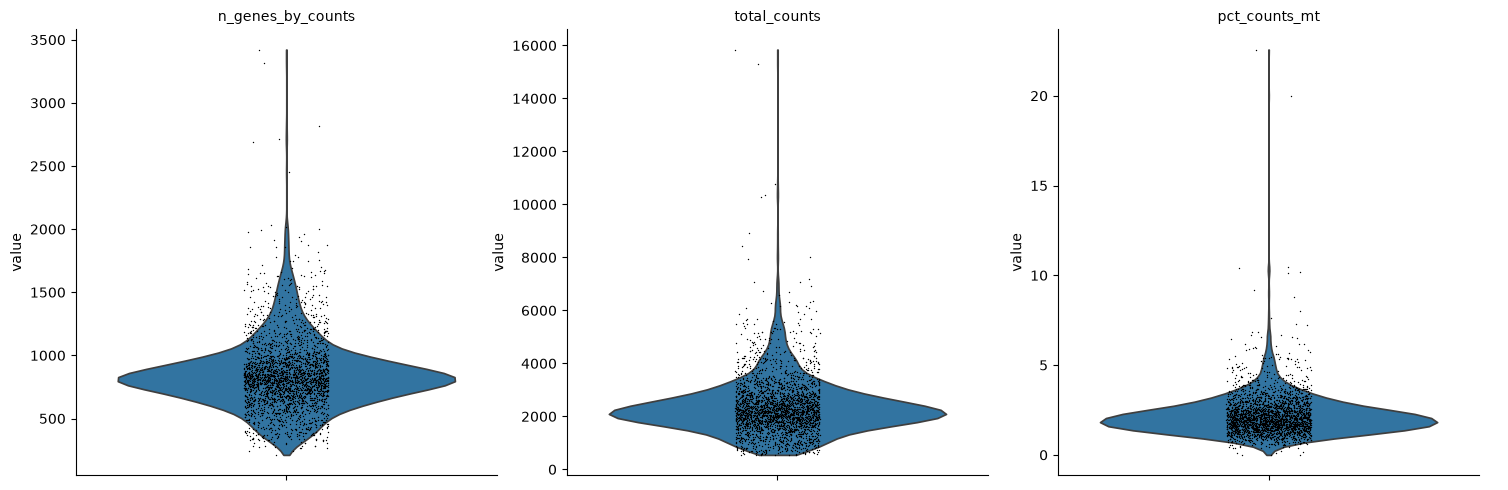

In [11]:
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"], multi_panel=True)

In [12]:
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

In [13]:
adata = adata[(adata.obs.n_genes_by_counts < 2500) & (adata.obs.pct_counts_mt < 5)].copy()

In [14]:
adata.layers["counts"] = adata.X.copy()

In [15]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: 'counts'

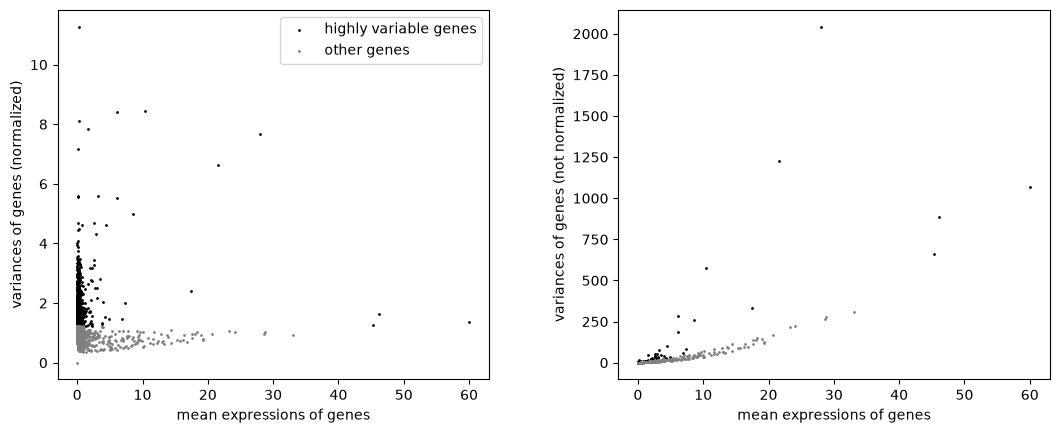

In [16]:
sc.pp.highly_variable_genes(adata, layer="counts", flavor="seurat_v3", n_top_genes=2000)
sc.pl.highly_variable_genes(adata)

In [17]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg'
    layers: 'counts'

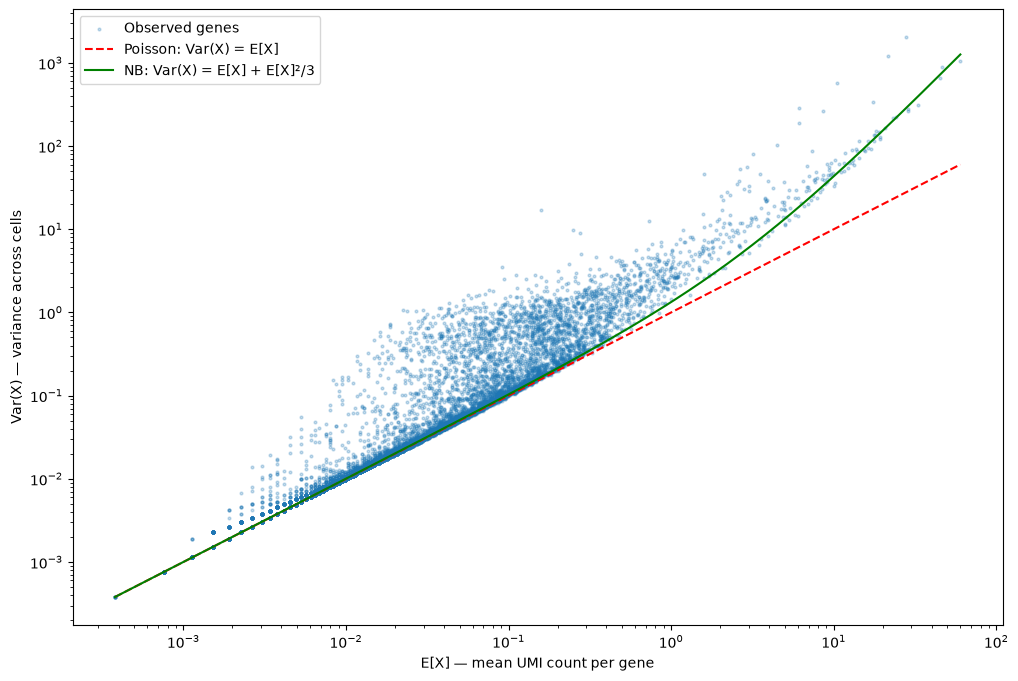

In [ ]:
plt.figure(figsize=(12, 8))

mean = adata.var["means"].to_numpy()
var = adata.var["variances"].to_numpy()
valid = (mean > 0) & (var > 0)

theta = 3

x = np.geomspace(mean[valid].min(), mean[valid].max(), 200)

plt.scatter(mean[valid], var[valid], s=4, alpha=0.25, label="Observed genes")

plt.plot(x, x, "r--", label="Poisson: Var(X) = E[X]")
plt.plot(x, x + x**2/theta, "g-", label=f"NB: Var(X) = E[X] + E[X]²/{theta}")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("E[X] - mean UMI count per gene")
plt.ylabel("Var(X) - variance across cells")
plt.legend()
plt.show()

In [19]:
sc.pp.normalize_total(adata, target_sum=1e4) # учитываем разный размер библиотеки. Нормализуем на глубину секвенирования
sc.pp.log1p(adata) # уменьшаем влияние сильно экспрессируемых генов

In [20]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p'
    layers: 'counts'

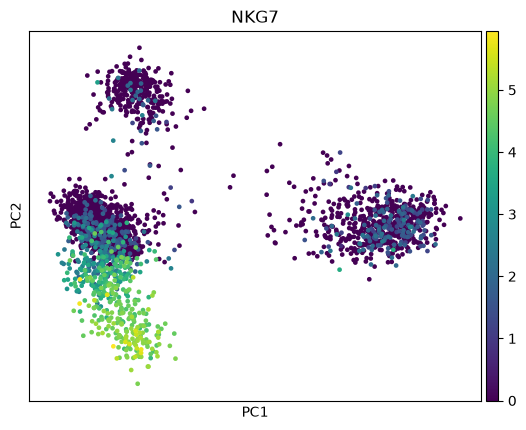

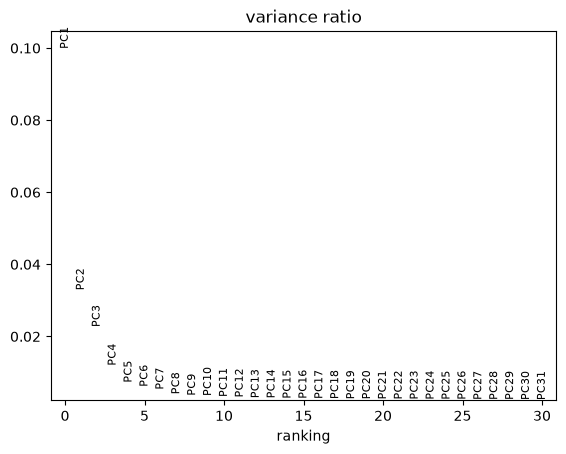

In [21]:
sc.tl.pca(adata, mask_var="highly_variable")
sc.pl.pca(adata, color="NKG7")
sc.pl.pca_variance_ratio(adata)

In [22]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'counts'

## Подумайте 

* Посмотрите что сейчас находится в слоях anndata. Что из себя представляют новые слои?
* По каким генам можно ещё делать QC?   
* Как лучше делать QC: по поиску генов по названиям в матрице или с помощью gtf/gff файла?
* Сколько есть генов на митохондриальной хросоме? Все ли они начинаются с mt?
* У человека митохондриальные гены начинаются с MT, у мыши с mt. Как начинаются митохондриальные гены у других организмов: у коров, собак, приматов?

1. Что сейчас в слоях? В `adata.layers` один слой - `counts`. Это копия исходных UMI counts, сохранённая до нормализации. В `adata.X` после этого лежат нормализованные и логарифмированные значения. Сырые числа лежат в `counts`.

In [23]:
adata.layers

Layers with keys: counts

2. 
- рибосомные гены (`RPS*`, `RPL*`), доля сильно зависит от типа клетки и от качества
- гены гемоглобина (`HBA1`, `HBA2`, `HBB`), показывают примесь эритроцитов
- `MALAT1` - ядерная РНК, её слишком много или слишком мало бывает у повреждённых клеток
- гены стресса (`FOS`, `JUN`, `HSPA1A`), растут, если клетки долго лежали при выделении

3. Лучше по gtf/gff, потому что в нём есть хромосома и тип гена, так что митохондриальные гены можно взять просто как гены на хромосоме `MT`. Поиск по названию зависит от того, как кто-то назвал гены.

In [24]:
adata.var_names[adata.var_names.str.startswith("MT")]

Index(['MTOR', 'MTHFR', 'MTFR1L', 'MTF1', 'MTF2', 'MTMR11', 'MTX1', 'MTR',
       'MTA3', 'MTIF2', 'MTHFD2', 'MTX2', 'MTERFD2', 'MTMR14', 'MTHFD2L',
       'MTRR', 'MTMR12', 'MTX3', 'MTCH1', 'MTO1', 'MTFR2', 'MTHFD1L', 'MTRF1L',
       'MTURN', 'MTERF', 'MTPN', 'MTMR8', 'MTM1', 'MTMR1', 'MTCP1', 'MTMR9',
       'MTUS1', 'MTFR1', 'MTERFD1', 'MTDH', 'MTBP', 'MTSS1', 'MTAP', 'MTPAP',
       'MTG1', 'MTCH2', 'MTA2', 'MTL5', 'MTMR2', 'MTERFD3', 'MTMR6', 'MTIF3',
       'MTRF1', 'MTHFD1', 'MTA1', 'MTMR10', 'MTFMT', 'MTHFS', 'MT3', 'MT2A',
       'MT1E', 'MT1F', 'MT1X', 'MTSS1L', 'MTHFSD', 'MTMR4', 'MTG2', 'MTMR3',
       'MTFP1', 'MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6',
       'MT-CO3', 'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB'],
      dtype='object')

4. У человека 37: 13 кодируют белки, 22 - тРНК, 2 - рРНК. В нашей матрице `MT-` генов 13 - только белок-кодирующие, тРНК и рРНК 10x не считает. Гены, у которых имя начинается с `MT` без дефиса (`MTOR`, `MT1A`, `MT2A`), - не митохондриальные. И наоборот, многие белки митохондрий (`MRPL*`, `MRPS*`) закодированы в ядре и на `MT-` не начинаются.

5. Всё зависит от аннотации: у приматов в аннотациях часто тоже `MT-`, а у коровы и собаки в Ensembl гены митохондрий называются без приставки: `ND1`, `COX1`, `CYTB`, `ATP6`

**Во всех заданиях если не сказано иного используйте анализ с использованием филтрации по QC и PCA с использованием HVG**

## Задание 1
Сделайте QC по предложенным вами генам/группам генов и постройти графики для всех QC - и тех что мы сделали сами и тех что вы предложили. 

Для каждой группы генов/гена рассчитайте долю UMI от общего количества UMI клетки.

Постройте для всех QC-метрик (включая рассчитанные на занятии):

1. Violin plot.
2. Гистограмму распределения:
   - X - значение QC-метрики;
   - Y - количество клеток.
3. Scatter plot зависимости количества обнаруженных генов от общего количества UMI.

**Вопросы:** Какие клетки выглядят подозрительными? Какие метрики могут свидетельствовать о низком качестве клетки? Почему высокая доля определённой группы генов не всегда означает плохое качество?


In [73]:
adata_raw = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")

hb_genes = ["HBA1", "HBA2", "HBB", "HBD", "HBG1", "HBG2", "HBE1", "HBZ", "HBM", "HBQ1"]

adata_raw.var["mt"] = adata_raw.var_names.str.startswith("MT-")
adata_raw.var["ribo"] = adata_raw.var_names.str.startswith(("RPS", "RPL"))
adata_raw.var["hb"] = adata_raw.var_names.isin(hb_genes)

sc.pp.calculate_qc_metrics(adata_raw, qc_vars=["mt", "ribo", "hb"], percent_top=None, inplace=True)

qc_metrics = ["n_genes_by_counts", "total_counts", "pct_counts_mt", "pct_counts_ribo", "pct_counts_hb"]
adata_raw.obs[qc_metrics].describe()

,n_genes_by_counts,total_counts,pct_counts_mt,pct_counts_ribo,pct_counts_hb
count,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000
mean,846.994074,2366.900391,2.215132,34.949211,0.001819
std,282.104964,1094.262085,1.165438,10.215296,0.032423
min,212.000000,548.000000,0.000000,1.055966,0.000000
25%,690.000000,1757.750000,1.536238,26.332963,0.000000
50%,817.000000,2197.000000,2.029639,36.769516,0.000000
75%,953.250000,2763.000000,2.640218,43.353328,0.000000
max,3422.000000,15844.000000,22.569027,59.441711,1.362948


In [74]:
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
adata.var["hb"] = adata.var_names.isin(hb_genes)
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo", "hb"], layer="counts", percent_top=None, inplace=True)

**1. Violin plot**

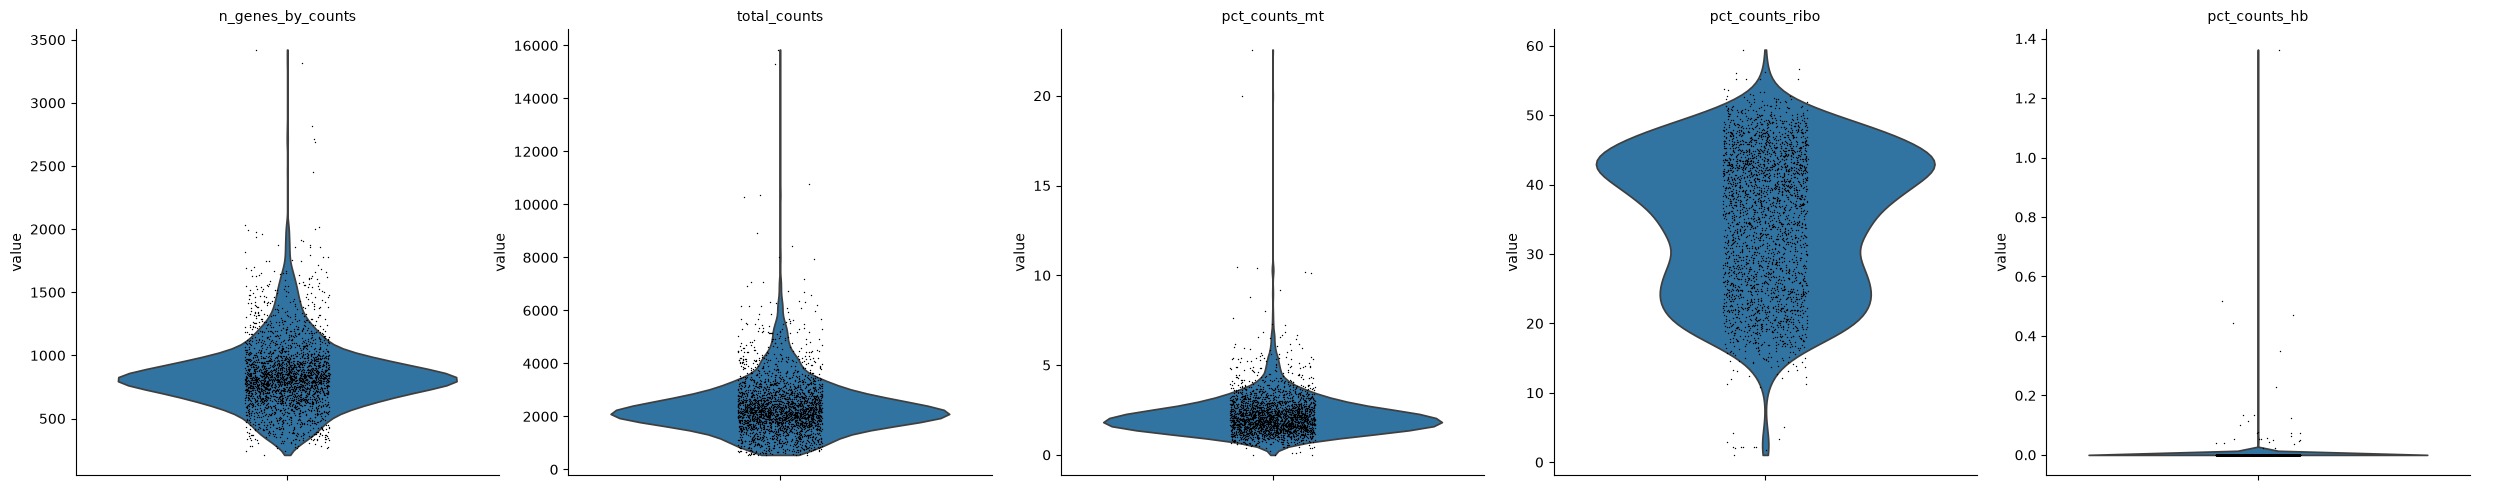

In [75]:
sc.pl.violin(adata_raw, qc_metrics, multi_panel=True)

**2. Гистограммы**

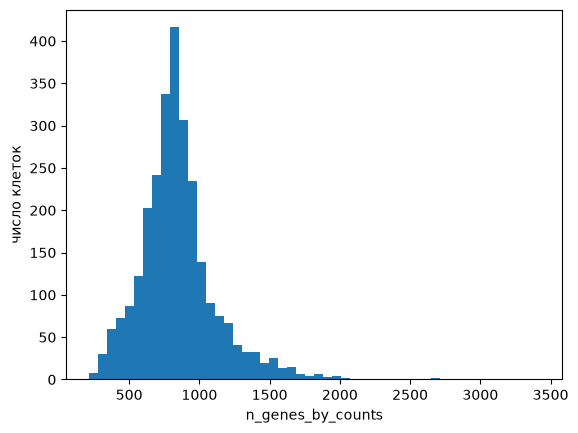

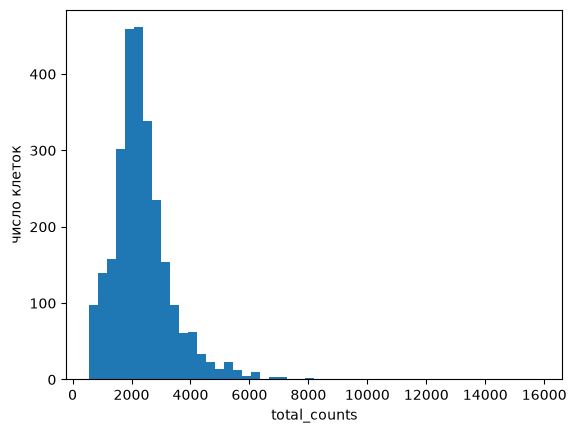

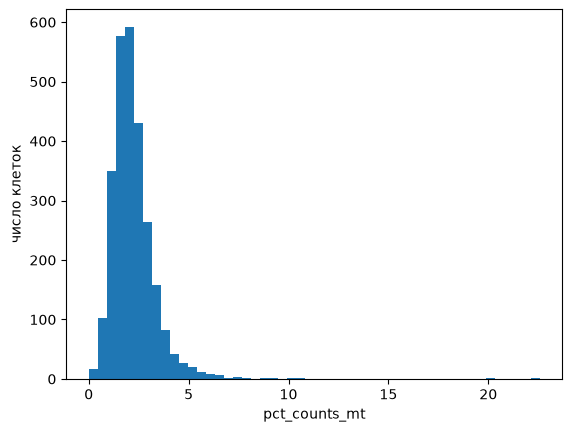

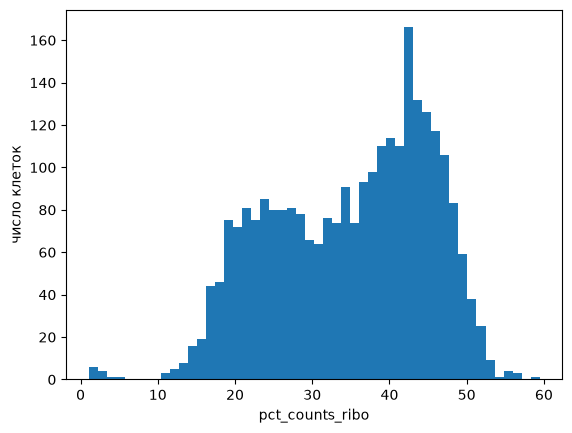

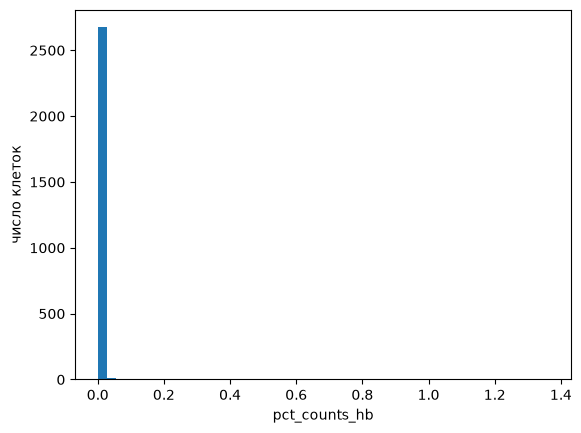

In [76]:
for m in qc_metrics:
    plt.hist(adata_raw.obs[m], bins=50)
    plt.xlabel(m)
    plt.ylabel("число клеток")
    plt.show()

**3. Число генов от числа UMI**

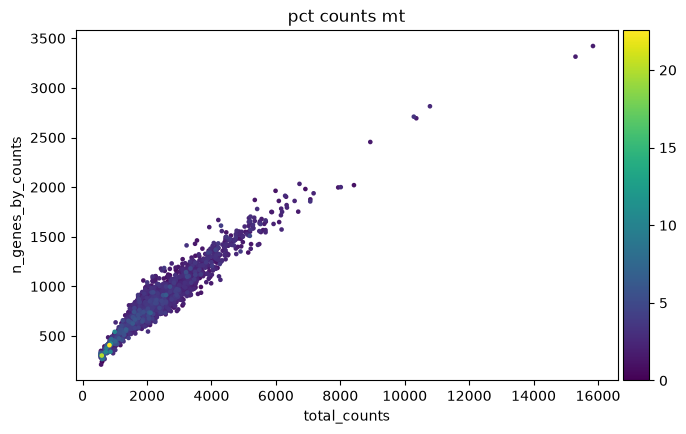

In [77]:
sc.pl.scatter(adata_raw, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt")

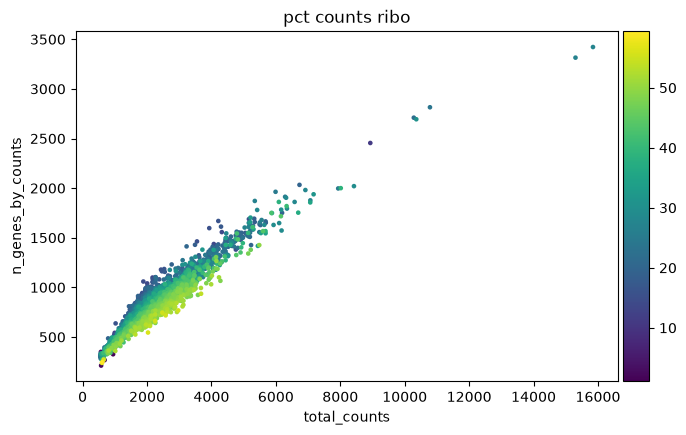

In [78]:
sc.pl.scatter(adata_raw, x="total_counts", y="n_genes_by_counts", color="pct_counts_ribo")

**Какие клетки выглядят подозрительными?**
- Клетки с высокой долей митохондриальных UMI (больше 5%, у некоторых до 20%). На scatter plot они сидят внизу слева: мало UMI и мало генов. Скорее всего, это повреждённые клетки
- Клетки с очень большим числом UMI и генов (больше 2500 генов, до 15 000 UMI). Это две клетки в одной капле
- Клетки с очень маленьким числом генов (около 200) - пустые капли или обрывки клеток
- Несколько клеток с почти нулевой долей рибосомных UMI (1–5%), когда у остальных 20–50%

Гемоглобин почти у всех клеток равен нулю (максимум около 1%), то есть примеси эритроцитов почти нет.

**Какие метрики говорят о плохом качестве?** Высокая `pct_counts_mt`, маленькие `total_counts` и `n_genes_by_counts` (особенно все три сразу), слишком большие `total_counts` и `n_genes_by_counts` (дублеты), выбросы по доле рибосомных генов.

**Почему высокая доля группы генов - не всегда плохо?** Потому что она может зависеть от типа клетки. На violin plot доля рибосомных генов имеет два пика: у лимфоцитов рибосомных генов много (около 40–50%), у моноцитов меньше (около 20–30%)

## Задание 2. Сравнение методов отбора HVG

Мы использовали `seurat_v3`. Повторите отбор HVG методом `seurat`, а также попробуйте использовать `sc.experimental.pp.highly_variable_genes`. 

Постройте PCA на генах, отобранных каждым методом. Для обоих PCA используйте одинаковую нормализованную и логарифмированную матрицу экспрессии.

Окрасьте клетки по экспрессии известных маркеров иммунных популяций:

| Популяция | Ген |
|---|---|
| T-клетки | `CD3D` |
| B-клетки | `MS4A1` |
| NK-клетки | `NKG7` |
| Моноциты | `LST1` |

Эти гены используются как ориентиры, а не как окончательные аннотации клеточных типов.

**Вопросы:** Насколько отличаются расположения клеток? Сохраняются ли группы клеток с характерной экспрессией маркеров? Сколько генов одновременно попало в оба набора HVG?


In [81]:
markers = ["CD3D", "MS4A1", "NKG7", "LST1"]

adata_seurat = adata.copy()
sc.pp.highly_variable_genes(adata_seurat, flavor="seurat", n_top_genes=2000)
sc.tl.pca(adata_seurat, mask_var="highly_variable")

adata_pearson = adata.copy()
sc.experimental.pp.highly_variable_genes(adata_pearson, layer="counts", n_top_genes=2000)
sc.tl.pca(adata_pearson, mask_var="highly_variable")

**seurat_v3**

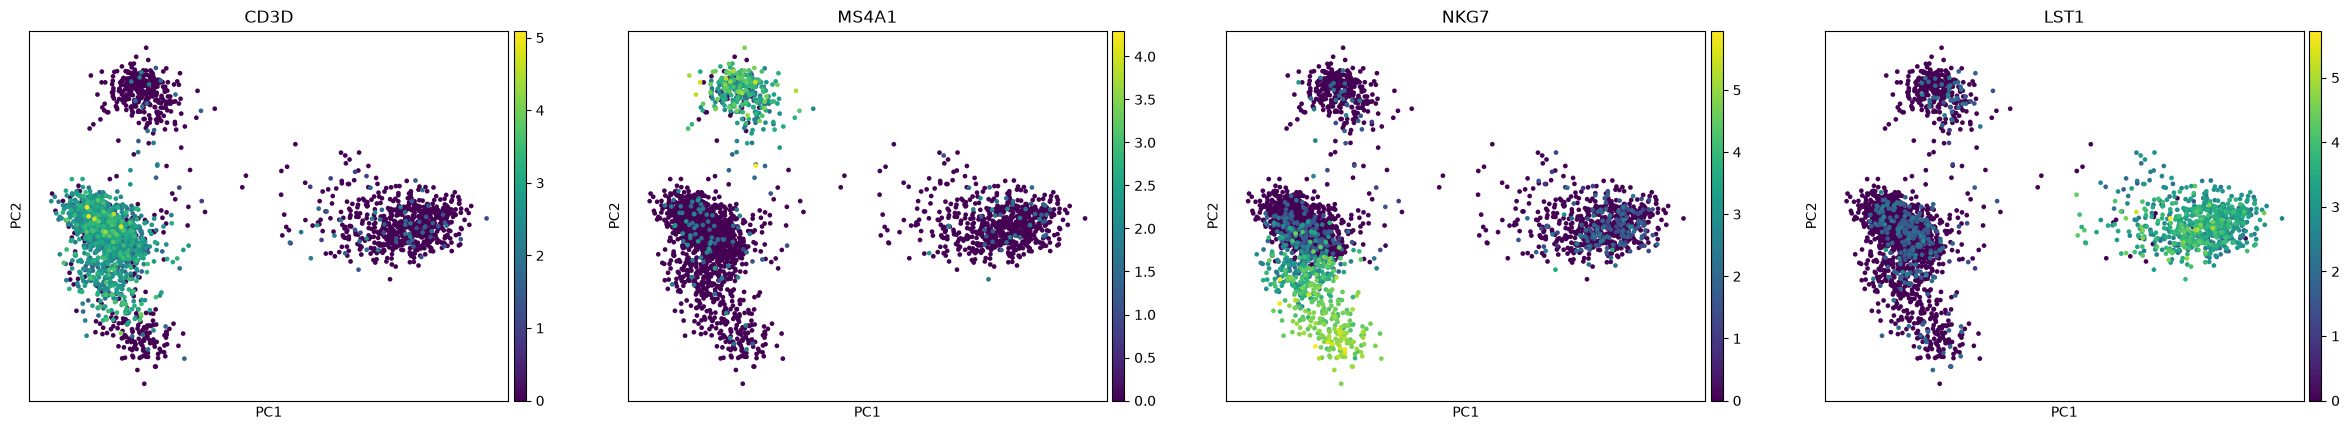

In [82]:
sc.pl.pca(adata, color=markers)

**seurat**

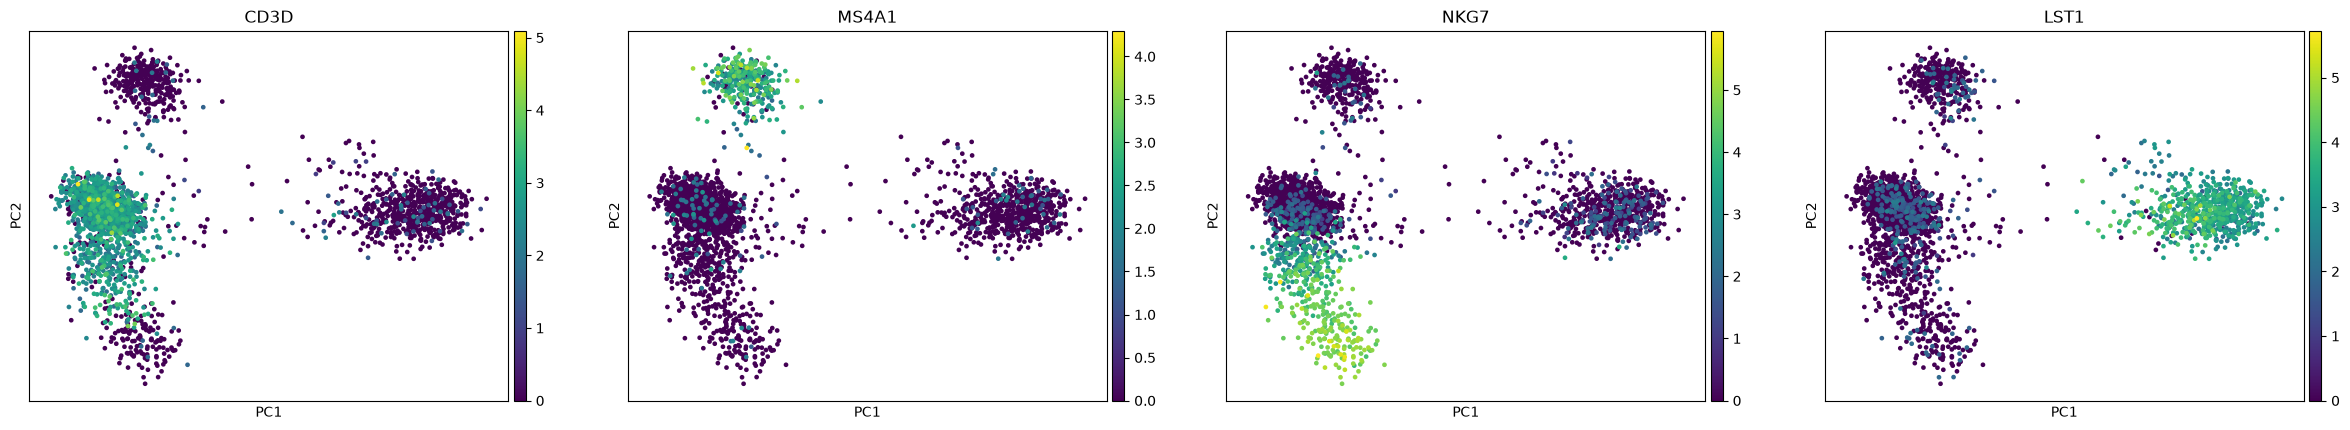

In [83]:
sc.pl.pca(adata_seurat, color=markers)

**Pearson residuals** (`sc.experimental`)

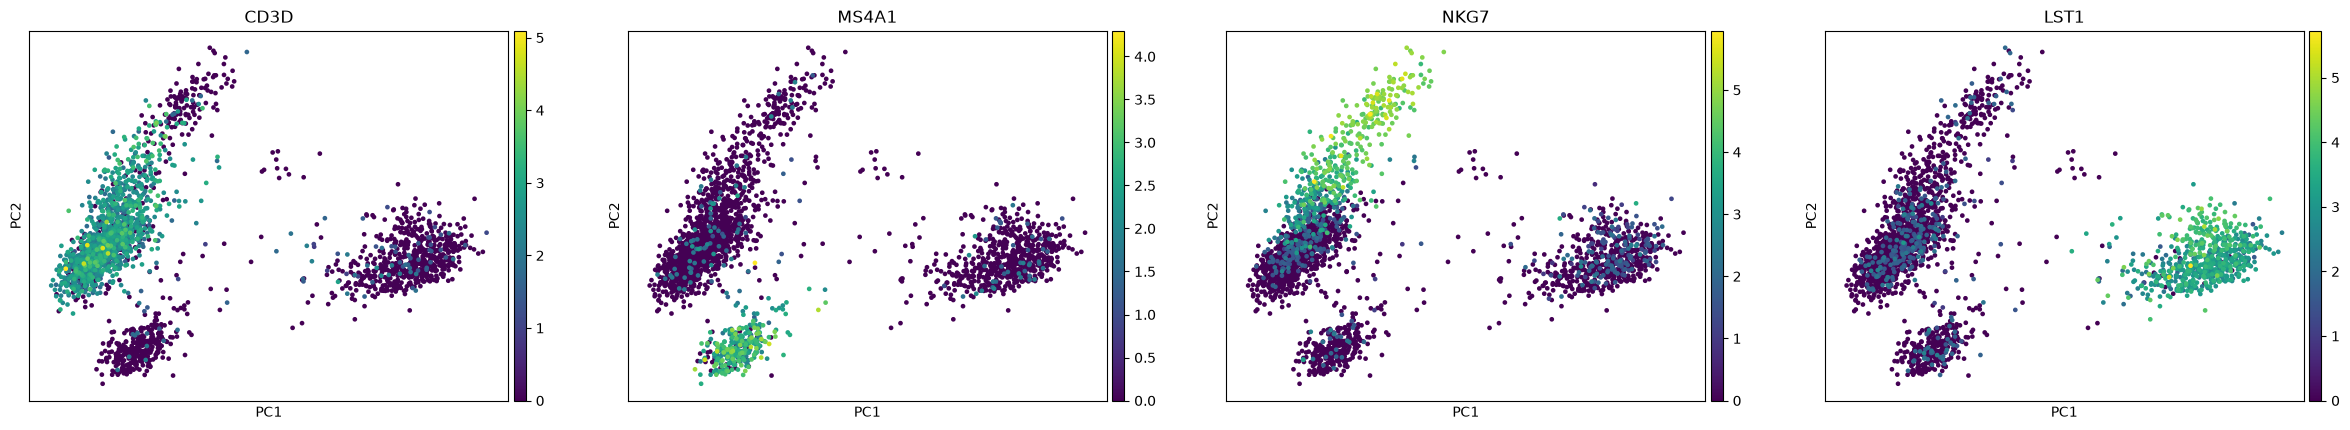

In [84]:
sc.pl.pca(adata_pearson, color=markers)

Сколько генов совпало:

In [88]:
hvg_v3 = set(adata.var_names[adata.var["highly_variable"]])
hvg_seurat = set(adata_seurat.var_names[adata_seurat.var["highly_variable"]])
hvg_pearson = set(adata_pearson.var_names[adata_pearson.var["highly_variable"]])

print("seurat_v3 и seurat:", len(hvg_v3 & hvg_seurat))
print("seurat_v3 и pearson:", len(hvg_v3 & hvg_pearson))
print("seurat и pearson:", len(hvg_seurat & hvg_pearson))
print("во всех трёх:", len(hvg_v3 & hvg_seurat & hvg_pearson))

seurat_v3 и seurat: 1505
seurat_v3 и pearson: 1402
seurat и pearson: 1291
во всех трёх: 1145


**Насколько отличаются расположения клеток?** У `seurat_v3` и `seurat` картинки почти одинаковые. У Pearson residuals картинка повёрнута (группы поменялись местами по PC2)

**Сохраняются ли группы?** Да. Во всех трёх вариантах видно те же группы: T-клетки (`CD3D`), отдельная группа B-клеток (`MS4A1`), NK-клетки (`NKG7`) на краю облака T-клеток и отдельная большая группа моноцитов (`LST1`)

**Сколько генов совпало?** `seurat_v3` и `seurat` - вывела выше

## Задание 3. PCA без отбора HVG

Повторите PCA, используя все гены, прошедшие QC, без ограничения набором HVG.

Сравните результат с PCA, построенным по 2000 HVG.

Используйте те же маркеры и одинаковые настройки нормализации и масштабирования данных.

**Вопросы:** Как изменилась структура клеток? Какие компоненты объясняют больше дисперсии? Почему использование всех доступных генов не обязательно делает PCA информативнее?


In [89]:
adata_all = adata.copy()
sc.tl.pca(adata_all, mask_var=None)

**Все гены**

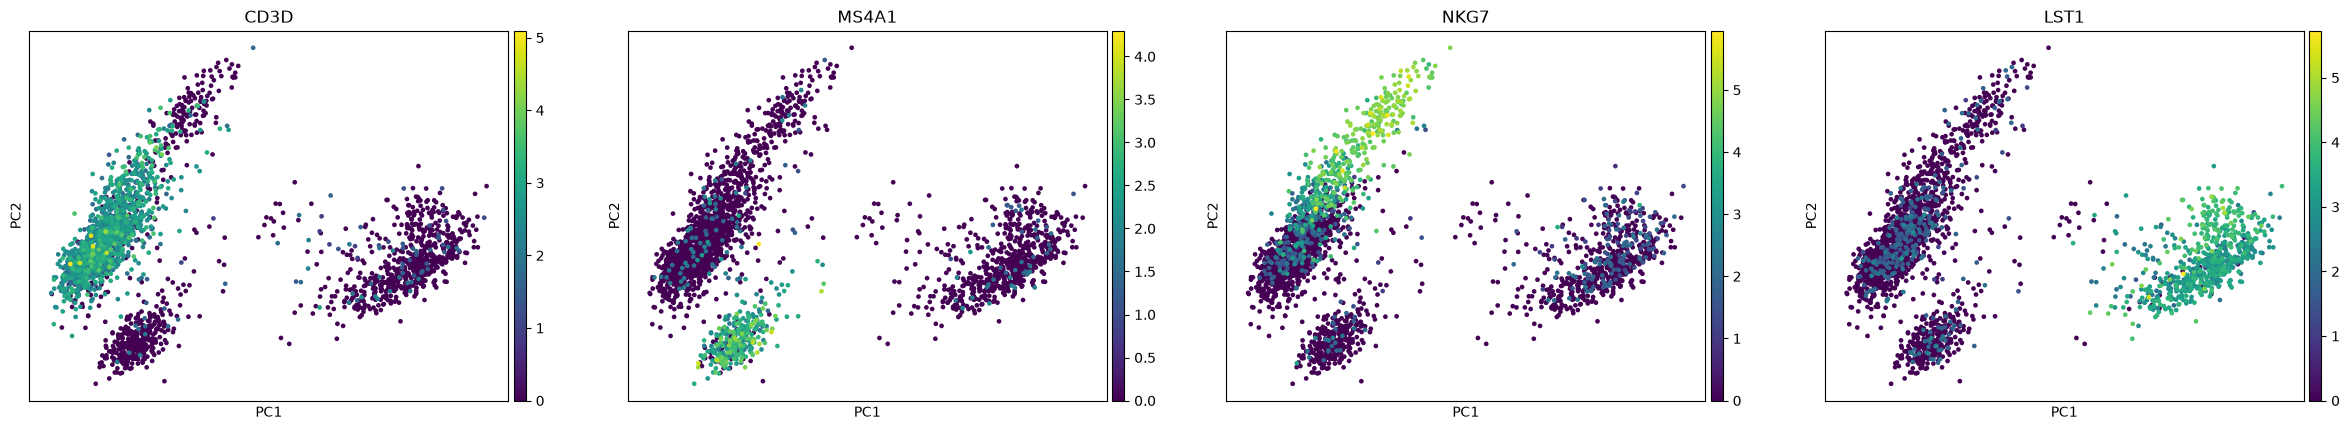

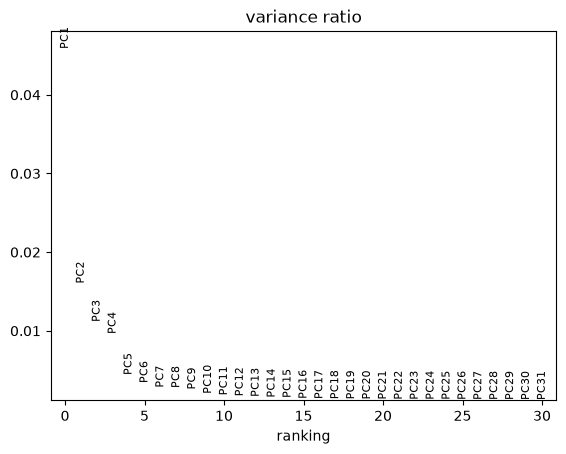

In [90]:
sc.pl.pca(adata_all, color=markers)
sc.pl.pca_variance_ratio(adata_all)

**2000 HVG**

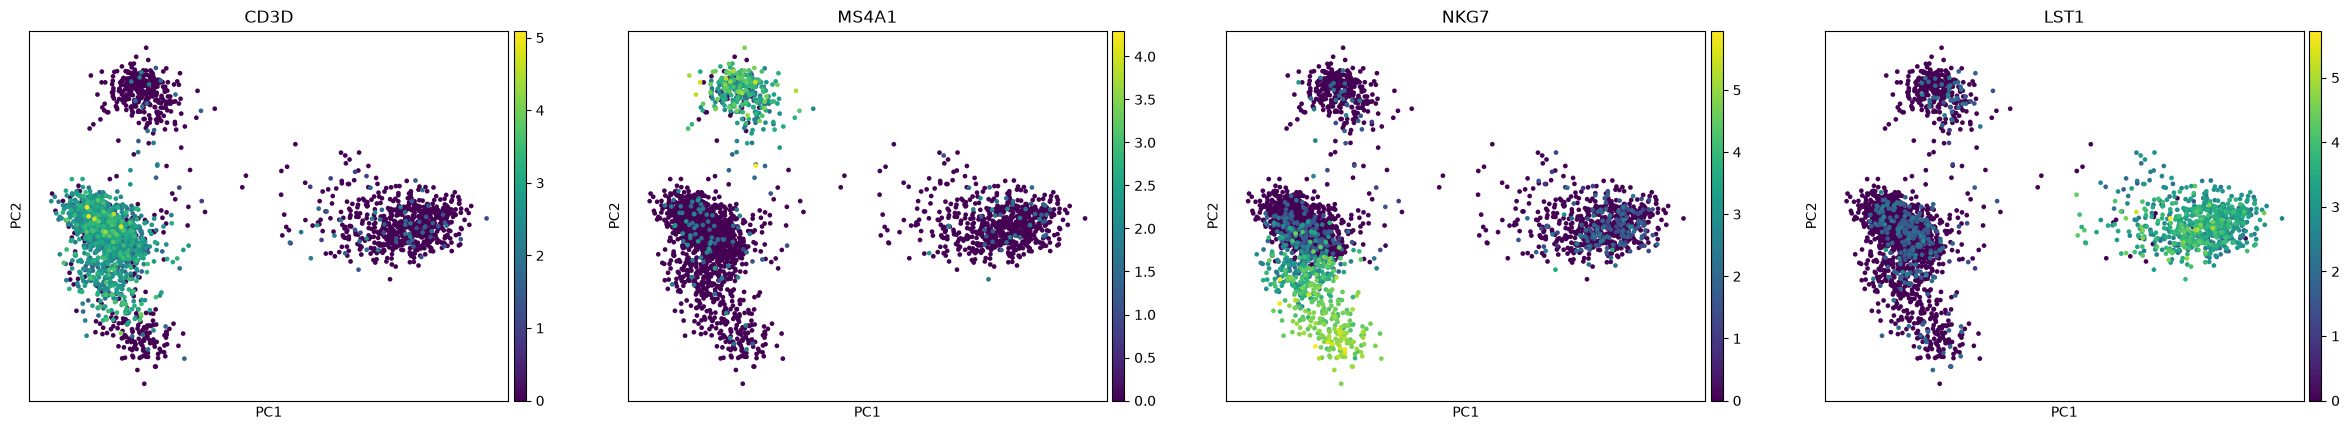

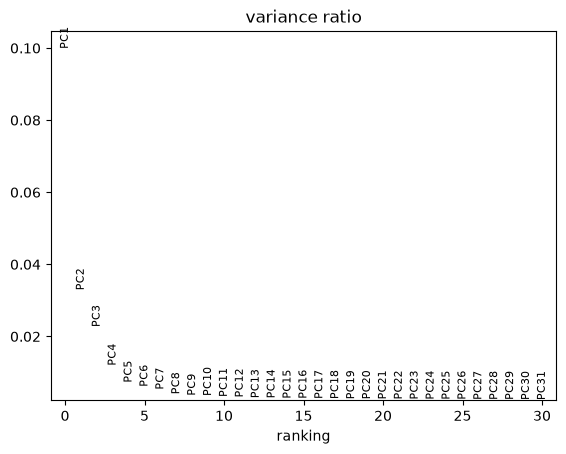

In [91]:
sc.pl.pca(adata, color=markers)
sc.pl.pca_variance_ratio(adata)

In [93]:
print("все гены, PC1-PC5:", adata_all.uns["pca"]["variance_ratio"][:5].round(3))
print("HVG, PC1-PC5:", adata.uns["pca"]["variance_ratio"][:5].round(3))
print("все гены, сумма 50 PC:", adata_all.uns["pca"]["variance_ratio"].sum().round(3))
print("HVG, сумма 50 PC:", adata.uns["pca"]["variance_ratio"].sum().round(3))

все гены, PC1-PC5: [0.046 0.016 0.011 0.01  0.004]
HVG, PC1-PC5: [0.1   0.033 0.023 0.012 0.007]
все гены, сумма 50 PC: 0.15
HVG, сумма 50 PC: 0.293


**Как изменилась структура?** Те же группы клеток остаются, картинка похожа (немного повёрнута)

**Какие компоненты объясняют больше дисперсии?** На HVG: PC1 - 10%, PC2 - 3.3%, все 50 PC вместе - 29%. На всех генах: PC1 - 4.6%, PC2 - 1.6%, все 50 PC - 15%

**Почему все гены не делают PCA лучше?** потому что больше разброс - просто шум (случайно поймали 0 или 1 UMI). Таких генов около 11 000, а полезных несколько сотен. Шум добавляет дисперсию, которая ничего не говорит о типах клеток, поэтому доля полезной дисперсии в первых компонентах падает


## Задание 4. HVG и уровень экспрессии

Получите два списка:

- Гены, отобранные как HVG.
- Гены, не попавшие в HVG.

В каждом списке найдите 50 генов с наибольшим средним количеством UMI на клетку по исходным counts.

Сравните средний уровень экспрессии, дисперсию и известные функции этих генов.

**Вопросы:** Обязательно ли HVG являются наиболее экспрессируемыми генами? Почему ген может иметь очень высокую экспрессию, но не попасть в HVG? Какие группы генов встречаются среди наиболее экспрессируемых?


In [94]:
hvg = adata.var[adata.var["highly_variable"]]
not_hvg = adata.var[~adata.var["highly_variable"]]

top_hvg = hvg.sort_values("means", ascending=False).head(50)
top_not_hvg = not_hvg.sort_values("means", ascending=False).head(50)

In [95]:
top_hvg[["means", "variances", "variances_norm"]]

,means,variances,variances_norm
MALAT1,60.036770,1066.965276,1.351536
TMSB4X,46.140258,883.683013,1.635578
B2M,45.289234,659.396403,1.253419
FTL,27.999621,2042.635191,7.673222
FTH1,21.535633,1224.966307,6.636166
ACTB,17.458681,334.519908,2.421864
LYZ,10.408264,575.359613,8.427471
CD74,8.579606,261.893357,4.973804
S100A4,7.343063,86.277788,2.017245
MT-CO2,6.888552,56.979611,1.450462


In [96]:
top_not_hvg[["means", "variances", "variances_norm"]]

,means,variances,variances_norm
RPL10,33.017437,307.568145,0.916197
RPL13,28.774071,280.650492,1.014675
RPL13A,28.644428,264.712352,0.963137
RPS2,24.092115,222.835273,1.032835
RPS6,23.293025,218.039625,1.059218
RPS18,20.609553,166.728798,0.959988
RPL11,19.285823,128.423394,0.810545
RPL32,19.239575,122.069999,0.773005
RPS3,19.013647,146.800724,0.944900
RPL19,18.272555,149.752383,1.018239


In [97]:
print("HVG: среднее", top_hvg["means"].mean().round(2), " дисперсия", top_hvg["variances"].mean().round(1), " variances_norm", top_hvg["variances_norm"].mean().round(2))
print("не HVG: среднее", top_not_hvg["means"].mean().round(2), " дисперсия", top_not_hvg["variances"].mean().round(1), " variances_norm", top_not_hvg["variances_norm"].mean().round(2))

HVG: среднее 7.15  дисперсия 173.2  variances_norm 2.88
не HVG: среднее 14.33  дисперсия 94.4  variances_norm 0.82


In [98]:
print("HVG:", list(top_hvg.index))
print("не HVG:", list(top_not_hvg.index))

HVG: ['MALAT1', 'TMSB4X', 'B2M', 'FTL', 'FTH1', 'ACTB', 'LYZ', 'CD74', 'S100A4', 'MT-CO2', 'HLA-DRA', 'S100A9', 'OAZ1', 'CST3', 'S100A6', 'LTB', 'SH3BGRL3', 'VIM', 'TYROBP', 'S100A8', 'LGALS1', 'COTL1', 'HLA-DPB1', 'SAT1', 'NKG7', 'HLA-DPA1', 'HLA-DRB1', 'CD37', 'IFITM2', 'AIF1', 'ARPC1B', 'LST1', 'IL32', 'UBB', 'FCER1G', 'CTSS', 'CCL5', 'S100A11', 'SRGN', 'S100A10', 'PSAP', 'GNLY', 'KLF6', 'ANXA1', 'FCN1', 'RBM3', 'GSTP1', 'GPX1', 'EIF3H', 'TYMP']
не HVG: ['RPL10', 'RPL13', 'RPL13A', 'RPS2', 'RPS6', 'RPS18', 'RPL11', 'RPL32', 'RPS3', 'RPL19', 'RPS12', 'RPLP1', 'RPL3', 'RPS27', 'RPS19', 'RPS14', 'EEF1A1', 'RPL18A', 'RPL28', 'MT-CO1', 'RPS4X', 'TMSB10', 'RPLP2', 'RPL21', 'RPL15', 'RPS3A', 'RPS15A', 'RPL23A', 'RPS27A', 'RPL12', 'RPL27A', 'RPL6', 'RPS8', 'RPL26', 'TPT1', 'RPS15', 'RPL14', 'RPL10A', 'RPL9', 'RPS7', 'RPL8', 'RPS9', 'RPS16', 'RPL29', 'RPS5', 'RPS23', 'RPL30', 'RPL7', 'RPL18', 'PTMA']


**Сравнение.** Средняя экспрессия у топ-50 не-HVG выше, а дисперсия ниже. Главное различие в нормированной дисперсии `variances_norm`, у не-HVG меньше ожидаемой.

**Функции генов.**
- Не HVG: большинство рибосомные белки (`RPL*`, `RPS*`), плюс `EEF1A1` (трансляция), `TPT1`, `PTMA`, `TMSB10`, `MT-CO1`
- HVG: маркеры типов клеток. `LYZ`, `S100A8`, `S100A9`, `CST3`, `FCN1`, `LST1` - моноциты; `HLA-DRA`, `CD74`, `HLA-DP*` - антиген-презентирующие клетки (B-клетки, моноциты); `NKG7`, `GNLY`, `CCL5` - NK и цитотоксические T-клетки; `LTB`, `IL32` - T-клетки.

**Обязательно ли HVG - самые экспрессируемые?** Нет. HVG - это гены, у которых разброс больше, чем ожидается при их среднем уровне

**Почему ген с высокой экспрессией может не попасть в HVG?** Если он одинаково высоко экспрессируется во всех клетках. Тогда его разброс - это только шум подсчёта.

**Какие группы среди самых экспрессируемых?** Рибосомные белки, факторы трансляции, цитоскелет (`ACTB`, `TMSB4X`, `TMSB10`), `B2M`, ферритины (`FTL`, `FTH1`), `MALAT1`, митохондриальные гены.

## Задание 5. Влияние QC-метрик на PCA

Постройте несколько PCA plots для случаев:

1. Не используя фильтрацию и QC и не используя поиск HVG.
2. Не используя фильтрацию и QC, но используя поиск HVG.
3. Используя фильтрацию и QC, но не используя поиск HVG.
4. Используя фильтрацию и QC и используя поиск HVG.

Окрашивайте клетки по:

1. `total_counts` - общее число UMI клетки.
2. `n_genes_by_counts` - число обнаруженных генов.
3. `pct_counts_mt` - доля митохондриальных UMI.
4. Доле рибосомных UMI из задания 1.

Дополнительно постройте scatter plot:

- X - `total_counts`
- Y - `n_genes_by_counts`
- цвет - `pct_counts_mt`

Теперь повторите анализ не используя фильтрацию и QC но используя HVG

**Вопросы:** Связано ли положение клеток на PCA с количеством зарегистрированных UMI? Есть ли направления, вдоль которых меняется доля митохондриальных транскриптов? Можно ли по этим графикам заподозрить, что технические факторы влияют на главные компоненты?

Вот функция, чтобы не писать одно и то же много раз:

In [101]:
def make_pca(ad, use_hvg):
    ad = ad.copy()
    ad.layers["counts"] = ad.X.copy()
    if use_hvg:
        sc.pp.highly_variable_genes(ad, layer="counts", flavor="seurat_v3", n_top_genes=2000)
    sc.pp.normalize_total(ad, target_sum=1e4)
    sc.pp.log1p(ad)
    if use_hvg:
        sc.tl.pca(ad, mask_var="highly_variable")
    else:
        sc.tl.pca(ad, mask_var=None)
    return ad


adata_qc = adata_raw.copy()
sc.pp.filter_cells(adata_qc, min_genes=200)
sc.pp.filter_genes(adata_qc, min_cells=3)
adata_qc = adata_qc[(adata_qc.obs.n_genes_by_counts < 2500) & (adata_qc.obs.pct_counts_mt < 5)].copy()

qc_colors = ["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"]


**1. Без QC, без HVG**

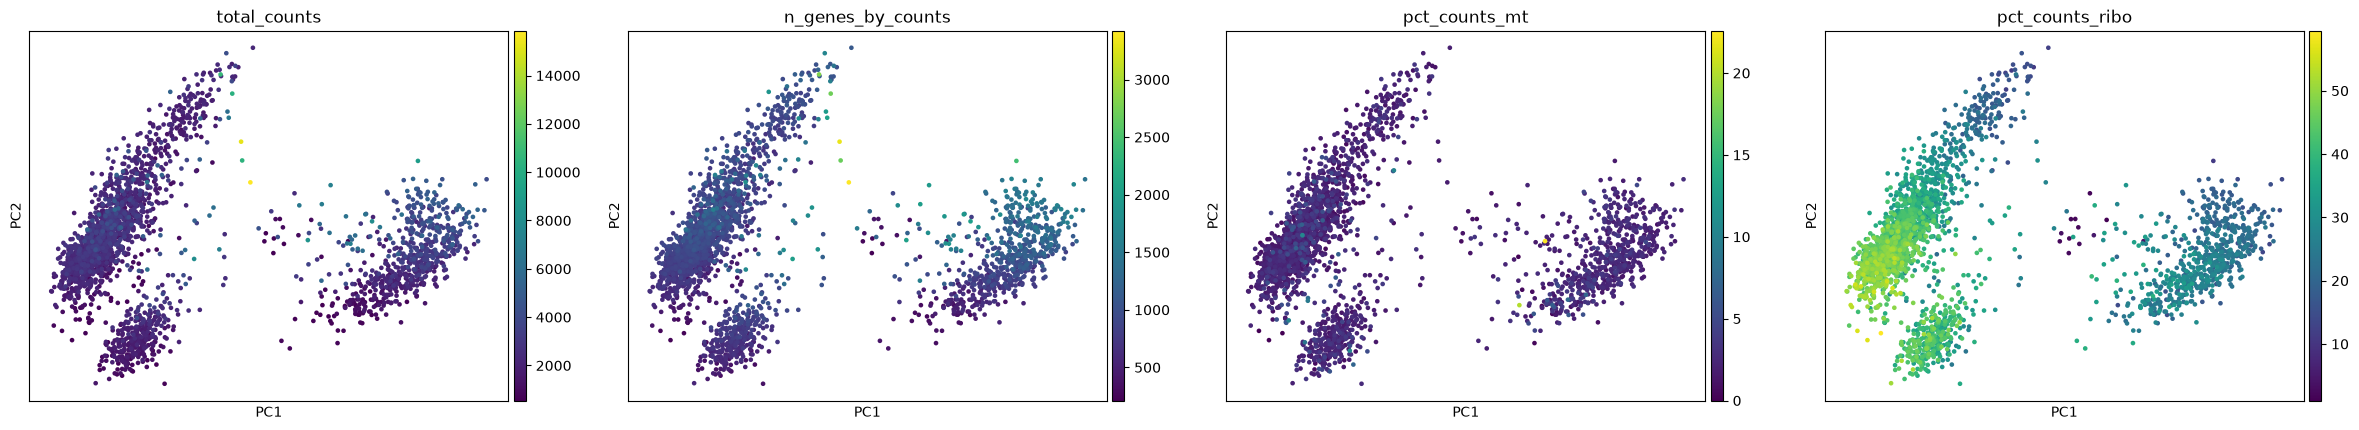

In [104]:
pca1 = make_pca(adata_raw, use_hvg=False)
sc.pl.pca(pca1, color=qc_colors)

**2. Без QC, с HVG**

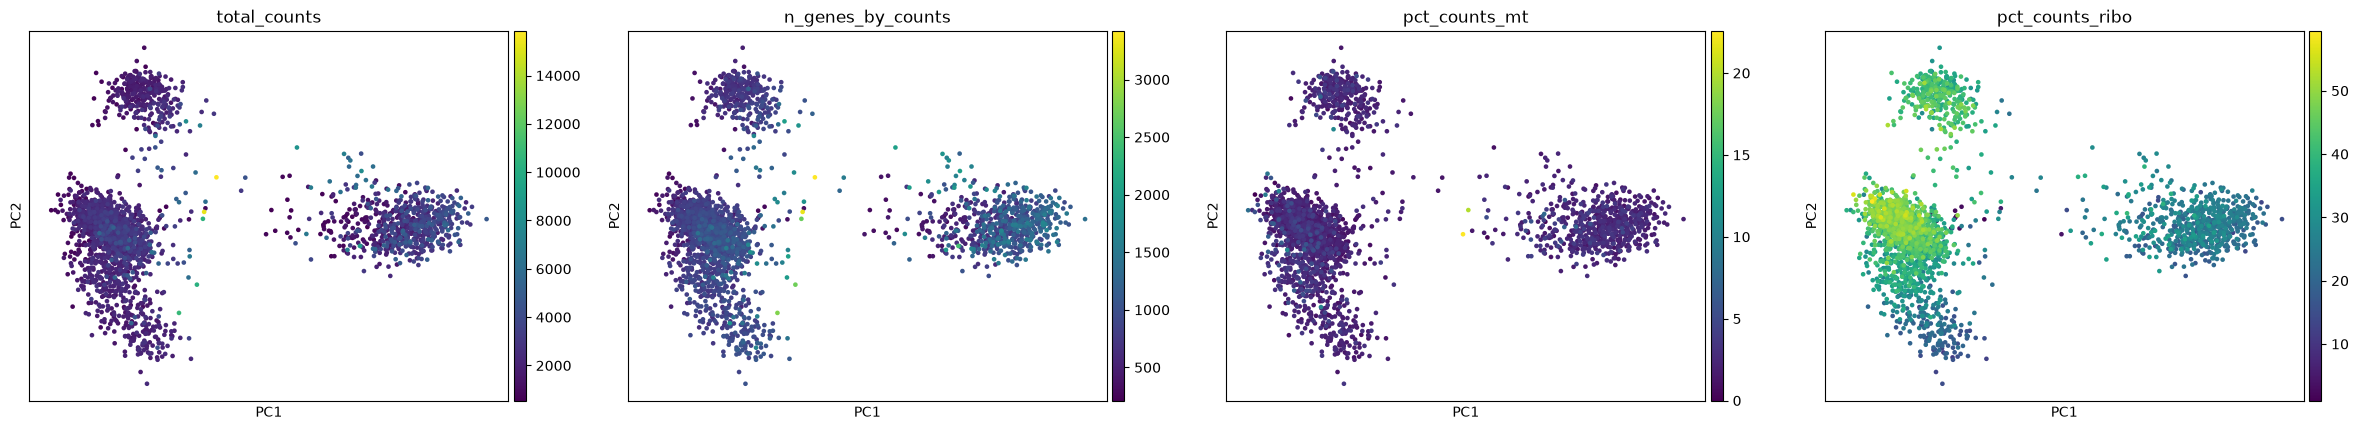

In [105]:
pca2 = make_pca(adata_raw, use_hvg=True)
sc.pl.pca(pca2, color=qc_colors)

**3. С QC, без HVG**

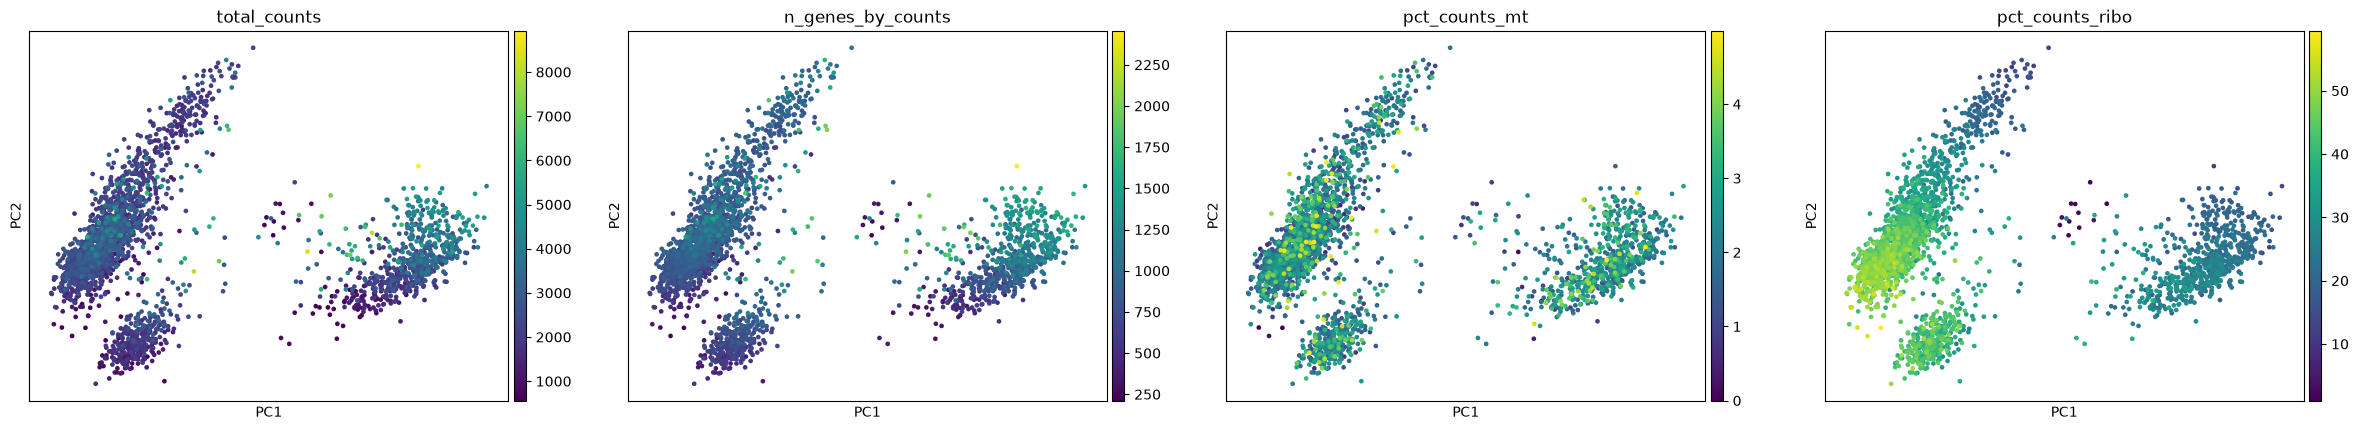

In [106]:
pca3 = make_pca(adata_qc, use_hvg=False)
sc.pl.pca(pca3, color=qc_colors)

**4. С QC, с HVG**

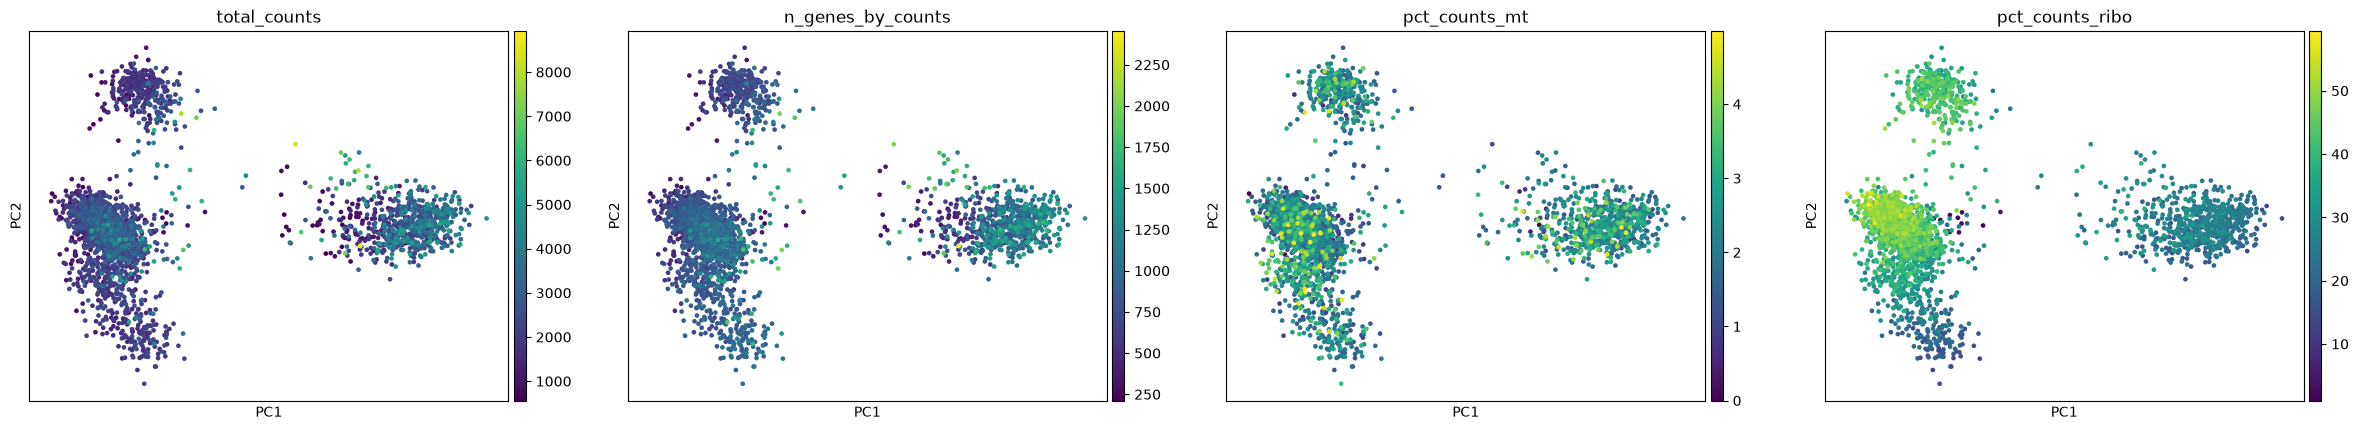

In [107]:
pca4 = make_pca(adata_qc, use_hvg=True)
sc.pl.pca(pca4, color=qc_colors)

**Scatter: UMI, гены и доля mt** - до и после фильтрации

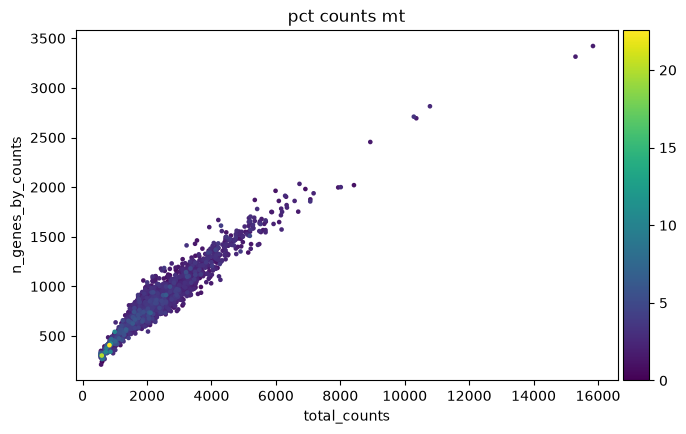

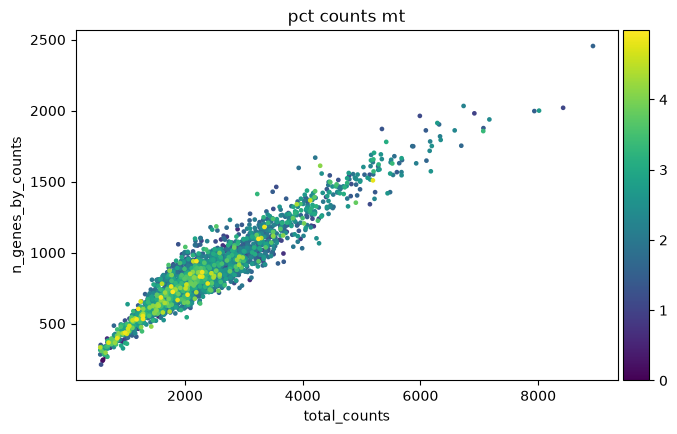

In [108]:
sc.pl.scatter(adata_raw, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt")
sc.pl.scatter(adata_qc, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt")

In [111]:
for name, ad in [("1. без QC, без HVG", pca1), ("2. без QC, с HVG", pca2), ("3. с QC, без HVG", pca3), ("4. с QC, с HVG", pca4)]:
    print()
    print(name)
    for m in qc_colors:
        r1 = np.corrcoef(ad.obsm["X_pca"][:, 0], ad.obs[m])[0, 1]
        r2 = np.corrcoef(ad.obsm["X_pca"][:, 1], ad.obs[m])[0, 1]
        print(f"{m}: PC1 {r1:.2f}, PC2 {r2:.2f}")
    


1. без QC, без HVG
total_counts: PC1 0.28, PC2 0.29
n_genes_by_counts: PC1 0.35, PC2 0.46
pct_counts_mt: PC1 0.11, PC2 -0.06
pct_counts_ribo: PC1 -0.75, PC2 -0.39

2. без QC, с HVG
total_counts: PC1 0.30, PC2 -0.08
n_genes_by_counts: PC1 0.34, PC2 -0.20
pct_counts_mt: PC1 0.08, PC2 -0.01
pct_counts_ribo: PC1 -0.66, PC2 0.33

3. с QC, без HVG
total_counts: PC1 0.31, PC2 0.22
n_genes_by_counts: PC1 0.37, PC2 0.40
pct_counts_mt: PC1 0.16, PC2 -0.02
pct_counts_ribo: PC1 -0.76, PC2 -0.41

4. с QC, с HVG
total_counts: PC1 0.33, PC2 -0.08
n_genes_by_counts: PC1 0.37, PC2 -0.20
pct_counts_mt: PC1 0.15, PC2 -0.01
pct_counts_ribo: PC1 -0.67, PC2 0.34


**Связано ли положение клеток с числом UMI?** Немного да. Корреляция PC1 с `total_counts` около 0.3, с числом генов - около 0.35. Но на графиках видно, что это из-за того, что моноциты (правая группа) крупнее и содержат больше РНК, чем лимфоциты

**Есть ли направление, вдоль которого меняется доля mt?** Нет, корреляция с PC1 и PC2 около 0, клетки с высокой долей mt не собираются в отдельный край облака

**Влияют ли технические факторы?**
- Сильнее всего с PC1 связана доля рибосомных UMI (корреляция −0.7) - у лимфоцитов рибосомных генов много, у моноцитов мало, а PC1 как раз отделяет моноциты от лимфоцитов
- Без HVG PC2 сильнее связана с числом генов (корреляция 0.4–0.46), и группы хуже разделяются. То есть на всех генах техническая глубина сильнее влезает в главные компоненты. С HVG эта связь падает до −0.2.
- Фильтрация в этих данных почти ничего не меняет на картинке PCA, потому что плохих клеток мало (около 60 из 2700)

В целом, в PBMC 3k главные компоненты в основном биологические, а технические факторы сильнее заметны, если не отбирать HVG.


## Задание 6. Какие гены формируют главные компоненты?

PCA строит новые признаки как линейные комбинации исходных генов.

Для первой компоненты:

$$
PC_1=a_1Z_1+a_2Z_2+\ldots+a_nZ_n
$$

Коэффициенты $a_i$ называются *loadings*.

Получите 10 генов с наибольшими положительными и 10 с наиболее отрицательными loadings для PC1 и PC2.

Постройте график loadings и графики экспрессии нескольких найденных генов на PCA.

**Вопросы:** Какие гены сильнее всего определяют PC1 и PC2? Связаны ли они с иммунными клеточными популяциями, клеточным циклом или QC-метриками? Можно ли биологически интерпретировать главные компоненты на основании этих генов?

In [112]:
import pandas as pd

loadings = pd.DataFrame(adata.varm["PCs"][:, :2], index=adata.var_names, columns=["PC1", "PC2"])

pc1 = loadings["PC1"].sort_values()
pc2 = loadings["PC2"].sort_values()

In [113]:
print("PC1, самые положительные:", list(pc1.tail(10).index[::-1]))
print("PC1, самые отрицательные:", list(pc1.head(10).index))
print()
print("PC2, самые положительные:", list(pc2.tail(10).index[::-1]))
print("PC2, самые отрицательные:", list(pc2.head(10).index))

PC1, самые положительные: ['LYZ', 'CST3', 'S100A9', 'TYROBP', 'S100A8', 'LGALS1', 'AIF1', 'LST1', 'FCER1G', 'FCN1']
PC1, самые отрицательные: ['LTB', 'IL32', 'MALAT1', 'IL7R', 'CCL5', 'CD2', 'CTSW', 'STK17A', 'ACAP1', 'CD247']

PC2, самые положительные: ['HLA-DRA', 'CD74', 'HLA-DPB1', 'HLA-DRB1', 'CD79A', 'HLA-DPA1', 'HLA-DQA1', 'HLA-DQB1', 'CD79B', 'HLA-DRB5']
PC2, самые отрицательные: ['NKG7', 'S100A4', 'CCL5', 'IL32', 'GNLY', 'CTSW', 'GZMA', 'CST7', 'SRGN', 'ANXA1']


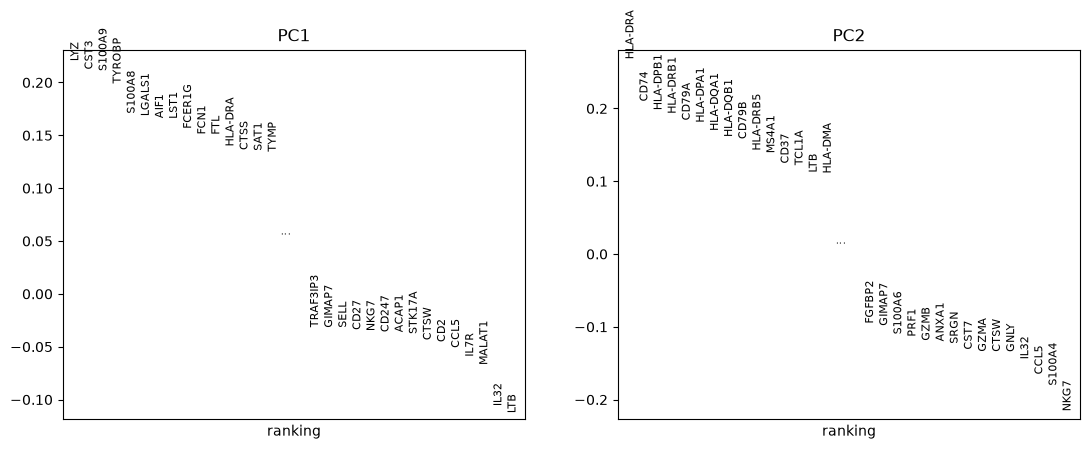

In [114]:
sc.pl.pca_loadings(adata, components="1,2")

Экспрессия нескольких генов с краёв PC1 и PC2:

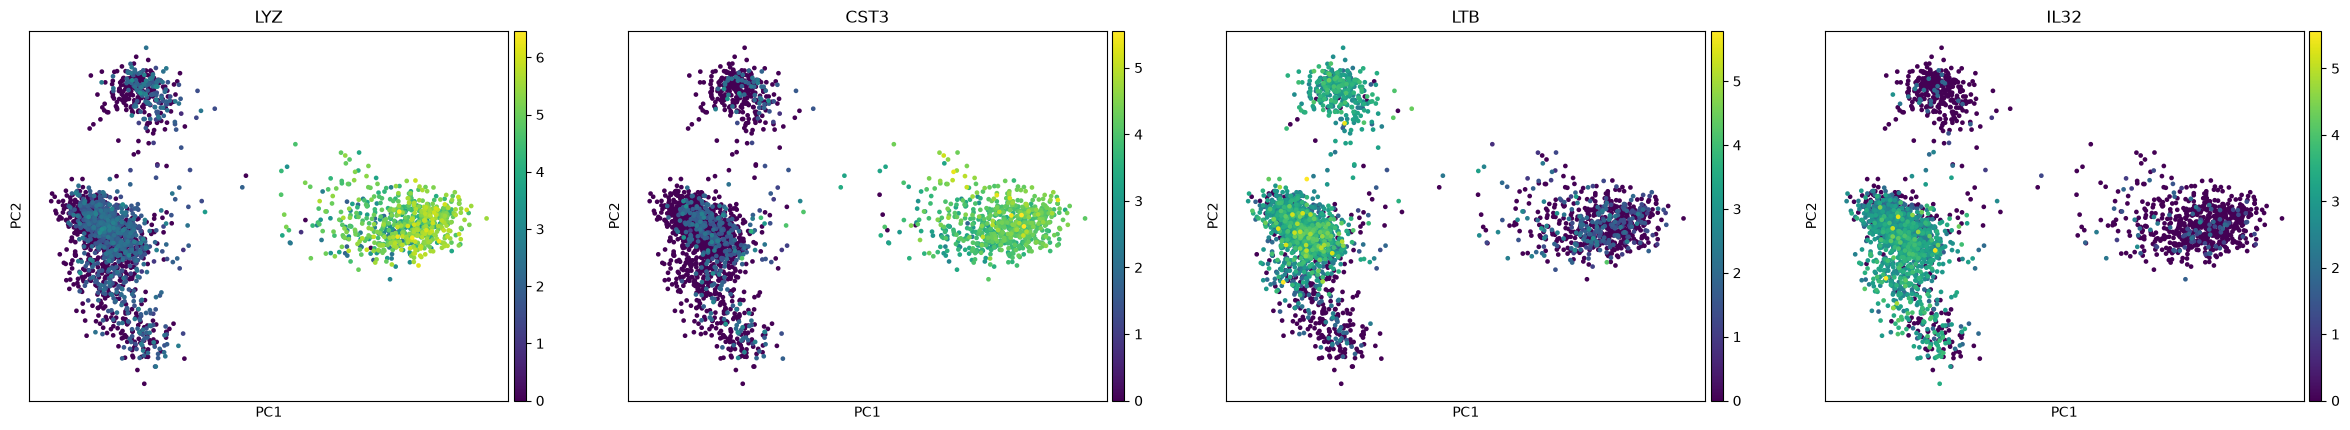

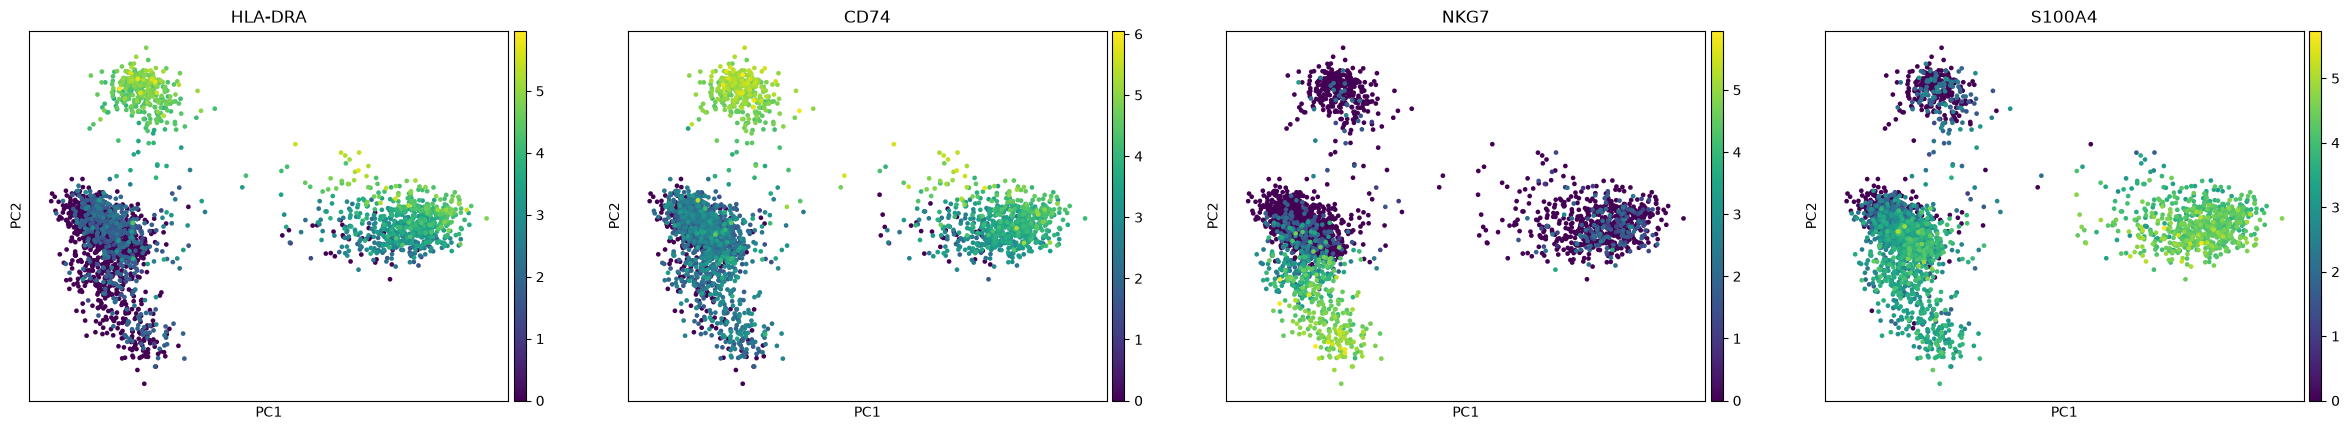

In [115]:
sc.pl.pca(adata, color=[pc1.index[-1], pc1.index[-2], pc1.index[0], pc1.index[1]])
sc.pl.pca(adata, color=[pc2.index[-1], pc2.index[-2], pc2.index[0], pc2.index[1]])

**Какие гены определяют PC1 и PC2? Можно ли интерпретировать компоненты?** 
- PC1, плюс: `LYZ`, `CST3`, `S100A9`, `S100A8`, `TYROBP`, `FCER1G`, `LST1`, `AIF1`, `FCN1` - гены моноцитов. Минус: `LTB`, `IL32`, `IL7R`, `CD2`, `CD247`, `CCL5` - гены T-клеток. **PC1 = моноциты vs лимфоцитов.**
- PC2, плюс: `HLA-DRA`, `CD74`, `HLA-DP*`, `HLA-DQ*`, `CD79A`, `CD79B` - B-клетки. Минус: `NKG7`, `GNLY`, `GZMA`, `CST7`, `CTSW`, `CCL5` - цитотоксические NK и CD8 T-клетки. **PC2 = B-клетки vs NK/цитотоксических клеток.**

**Связаны ли они с типами клеток, клеточным циклом или QC?** С типами иммунных клеток. Генов клеточного цикла и митохондриальных генов в топе нет. Из технических сюда попал только `MALAT1` (минус PC1)

## Задание 7
- Постройте график PCA не используя логарифмирование log1p
- Постройте график PCA не используя логарифмирование log1p и нормализацию normalize
- Попробуйте дополнительно к нормализации и логарифмированию использовать `sc.pp.scale(adata)`

`sc.pp.scale(adata)` делает стандартизацию генов по столбцам клеток. 

**Вопросы:** Что сильнее влияет на PCA - нормализация или логарифмирование? Сильно ли помогает scale? Что нам даёт каждая процедура: логарифмирование, нормализация, стандартизация; как они влияют на PCA? Все ли их нужно делать перед PCA?

In [117]:
colors = markers + ["total_counts"]

#только нормализация
a_norm = adata.copy()
a_norm.X = a_norm.layers["counts"].copy()
sc.pp.normalize_total(a_norm, target_sum=1e4)
sc.tl.pca(a_norm, mask_var="highly_variable")

#без нормализации и без log1p
a_counts = adata.copy()
a_counts.X = a_counts.layers["counts"].copy()
sc.tl.pca(a_counts, mask_var="highly_variable")

#только log1p
a_log = adata.copy()
a_log.X = a_log.layers["counts"].copy()
sc.pp.log1p(a_log)
sc.tl.pca(a_log, mask_var="highly_variable")

#нормализация+logp +scale
a_scale = adata.copy()
sc.pp.scale(a_scale)
sc.tl.pca(a_scale, mask_var="highly_variable")

/home/anna/miniconda3/envs/sc_pbmc/lib/python3.11/functools.py:909: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


**normalize + log1p**

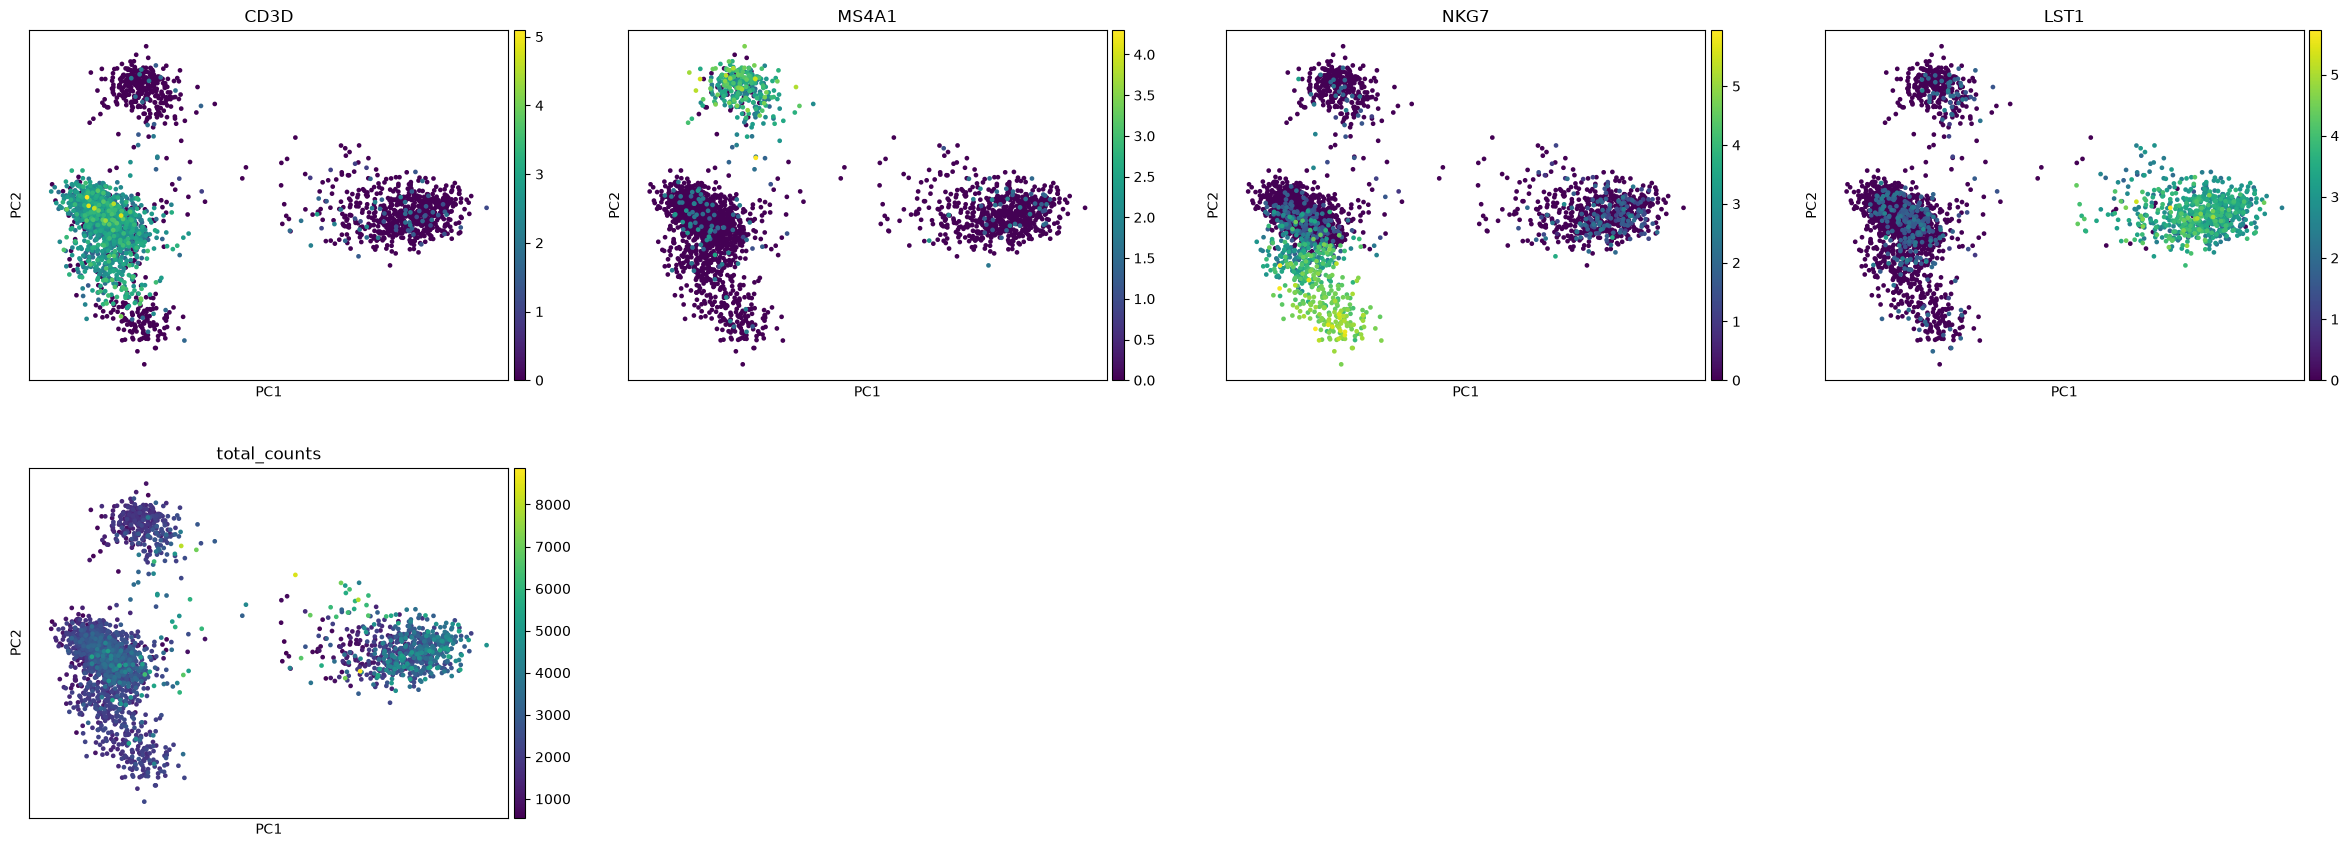

In [118]:
sc.pl.pca(adata, color=colors)

**Только normalize, без log1p**

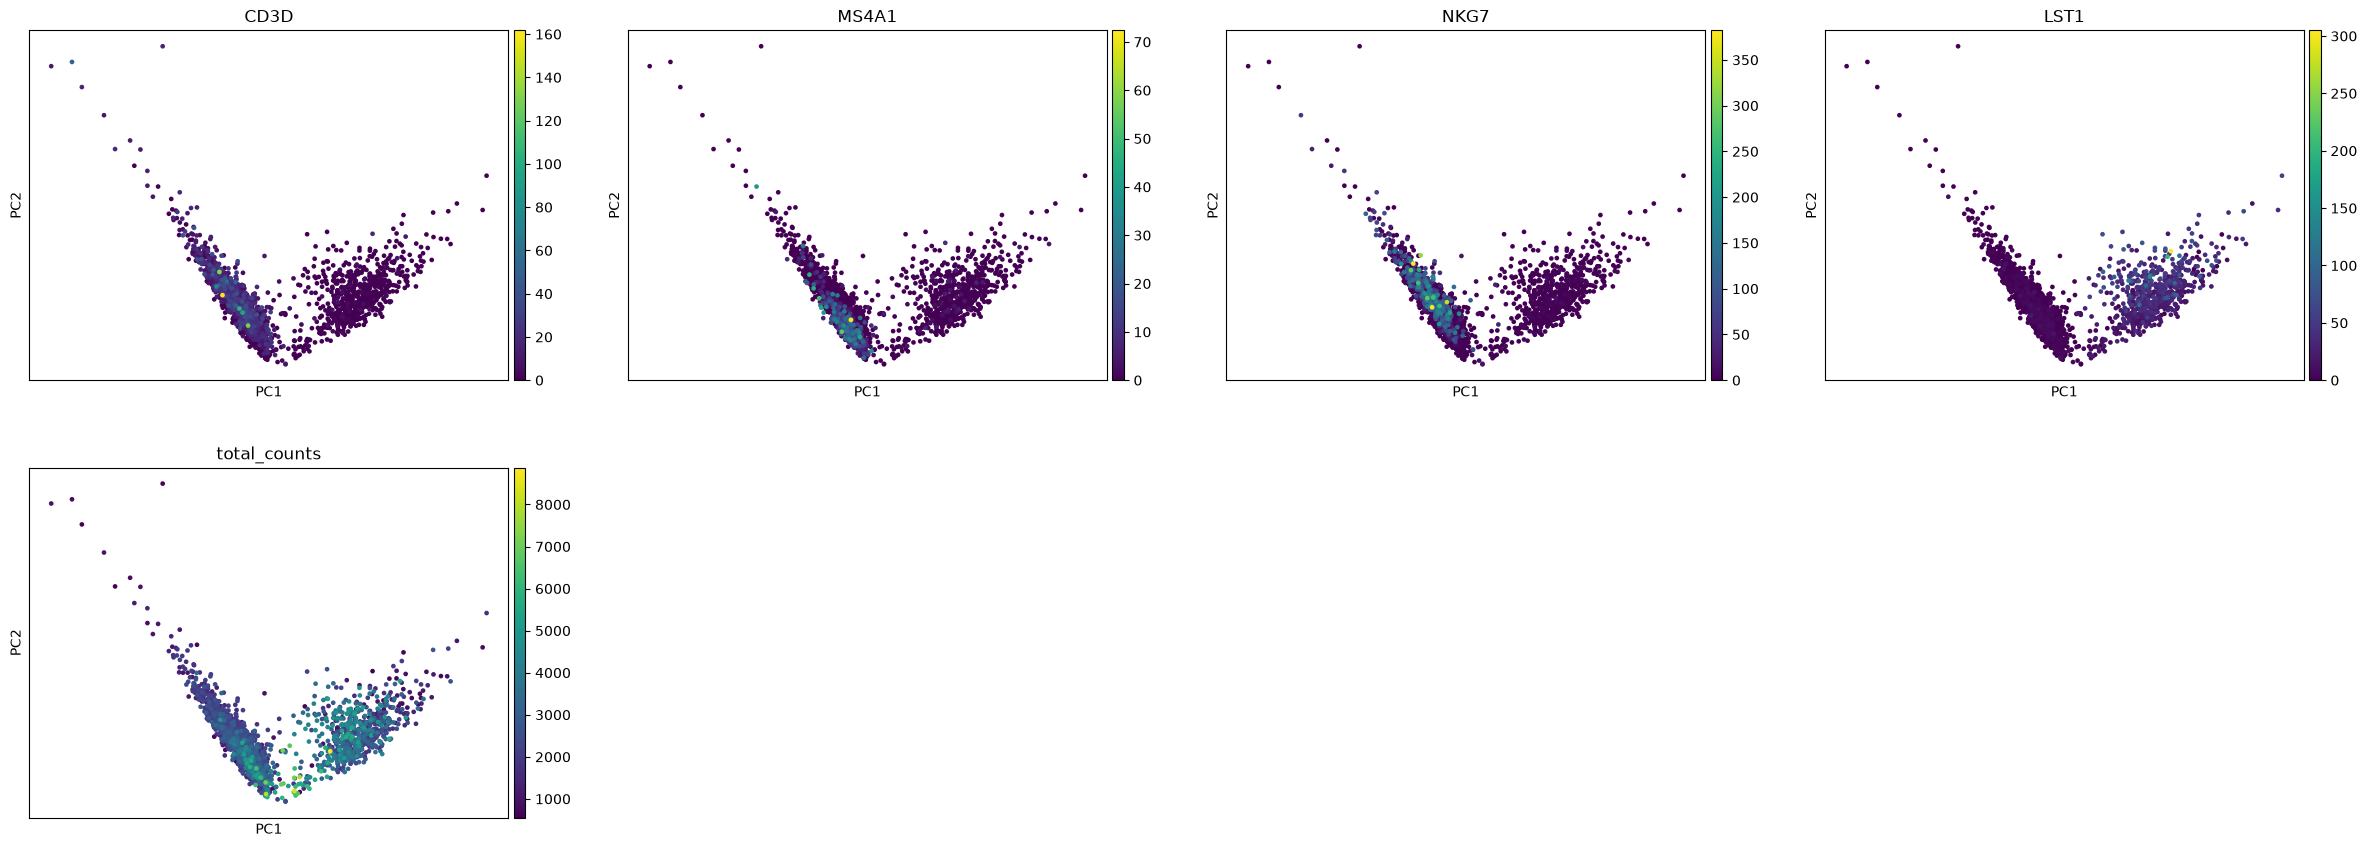

In [119]:
sc.pl.pca(a_norm, color=colors)

**Без normalize и без log1p**

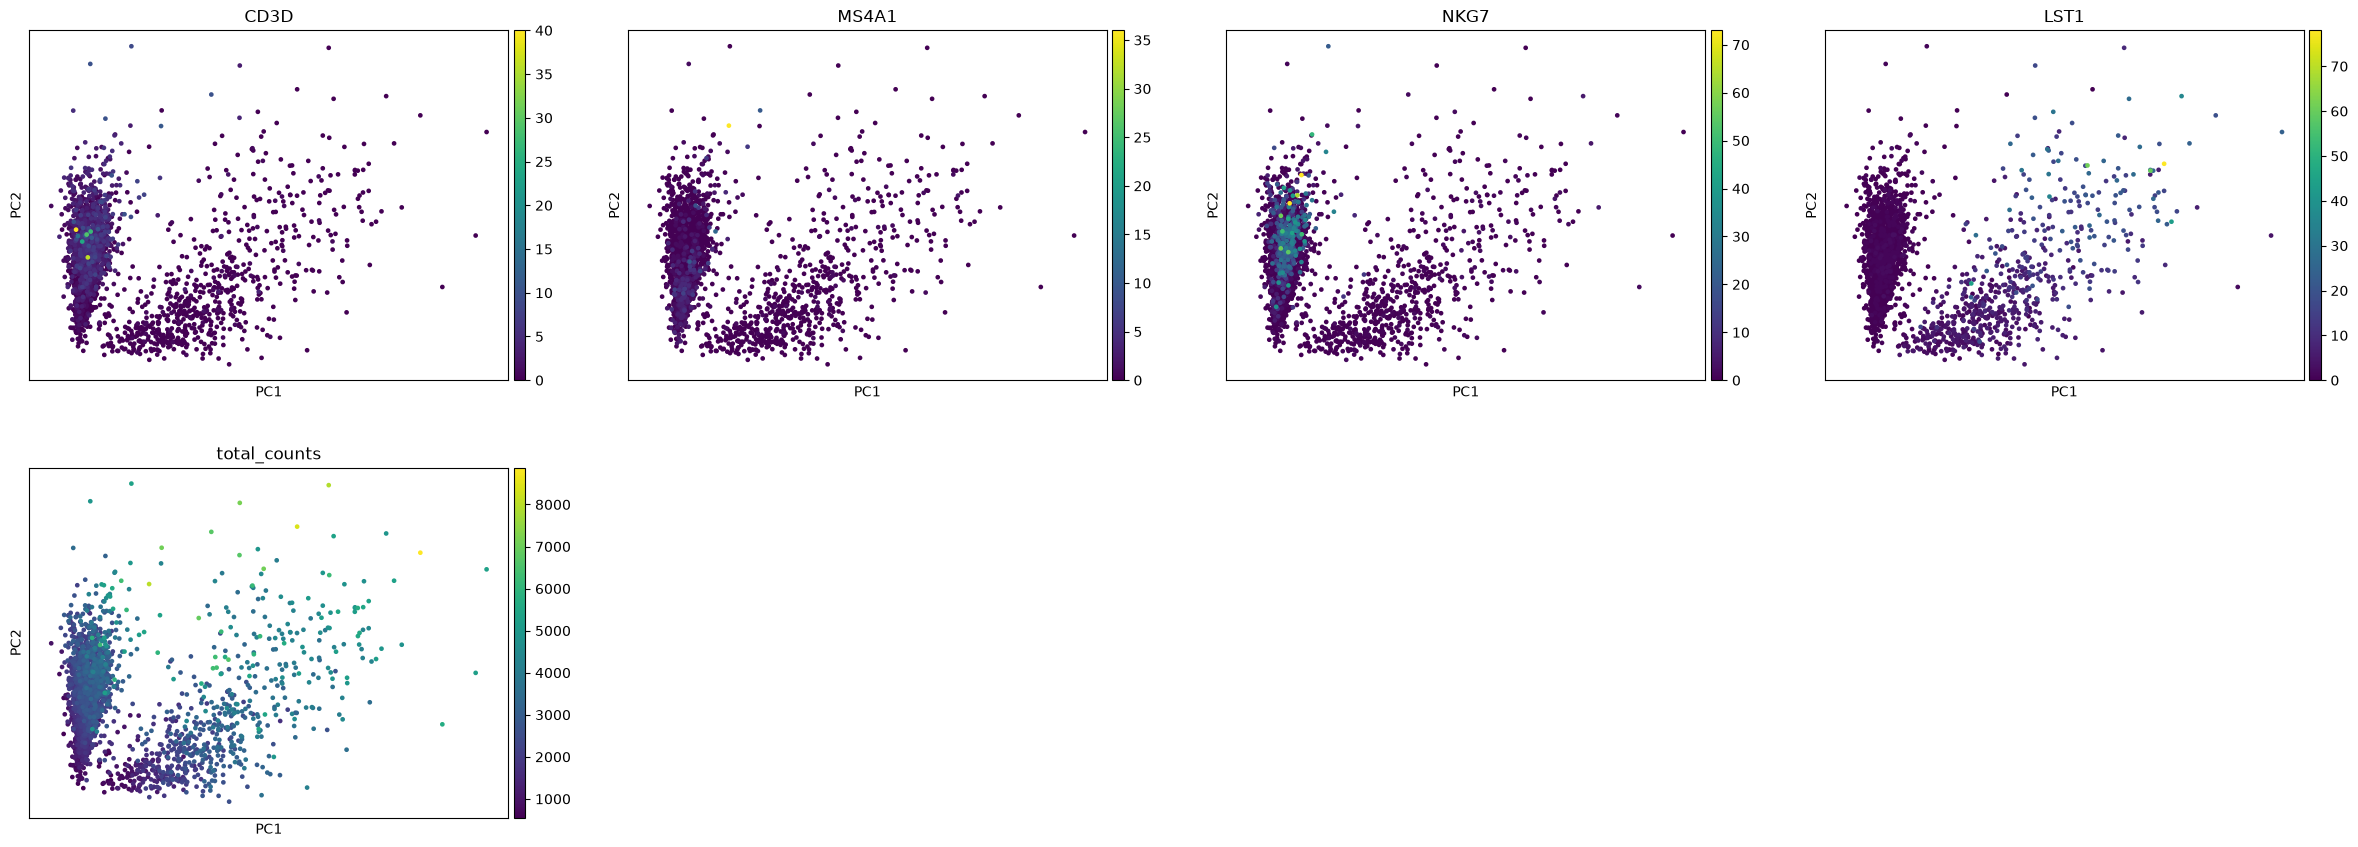

In [120]:
sc.pl.pca(a_counts, color=colors)

**Только log1p, без normalize**

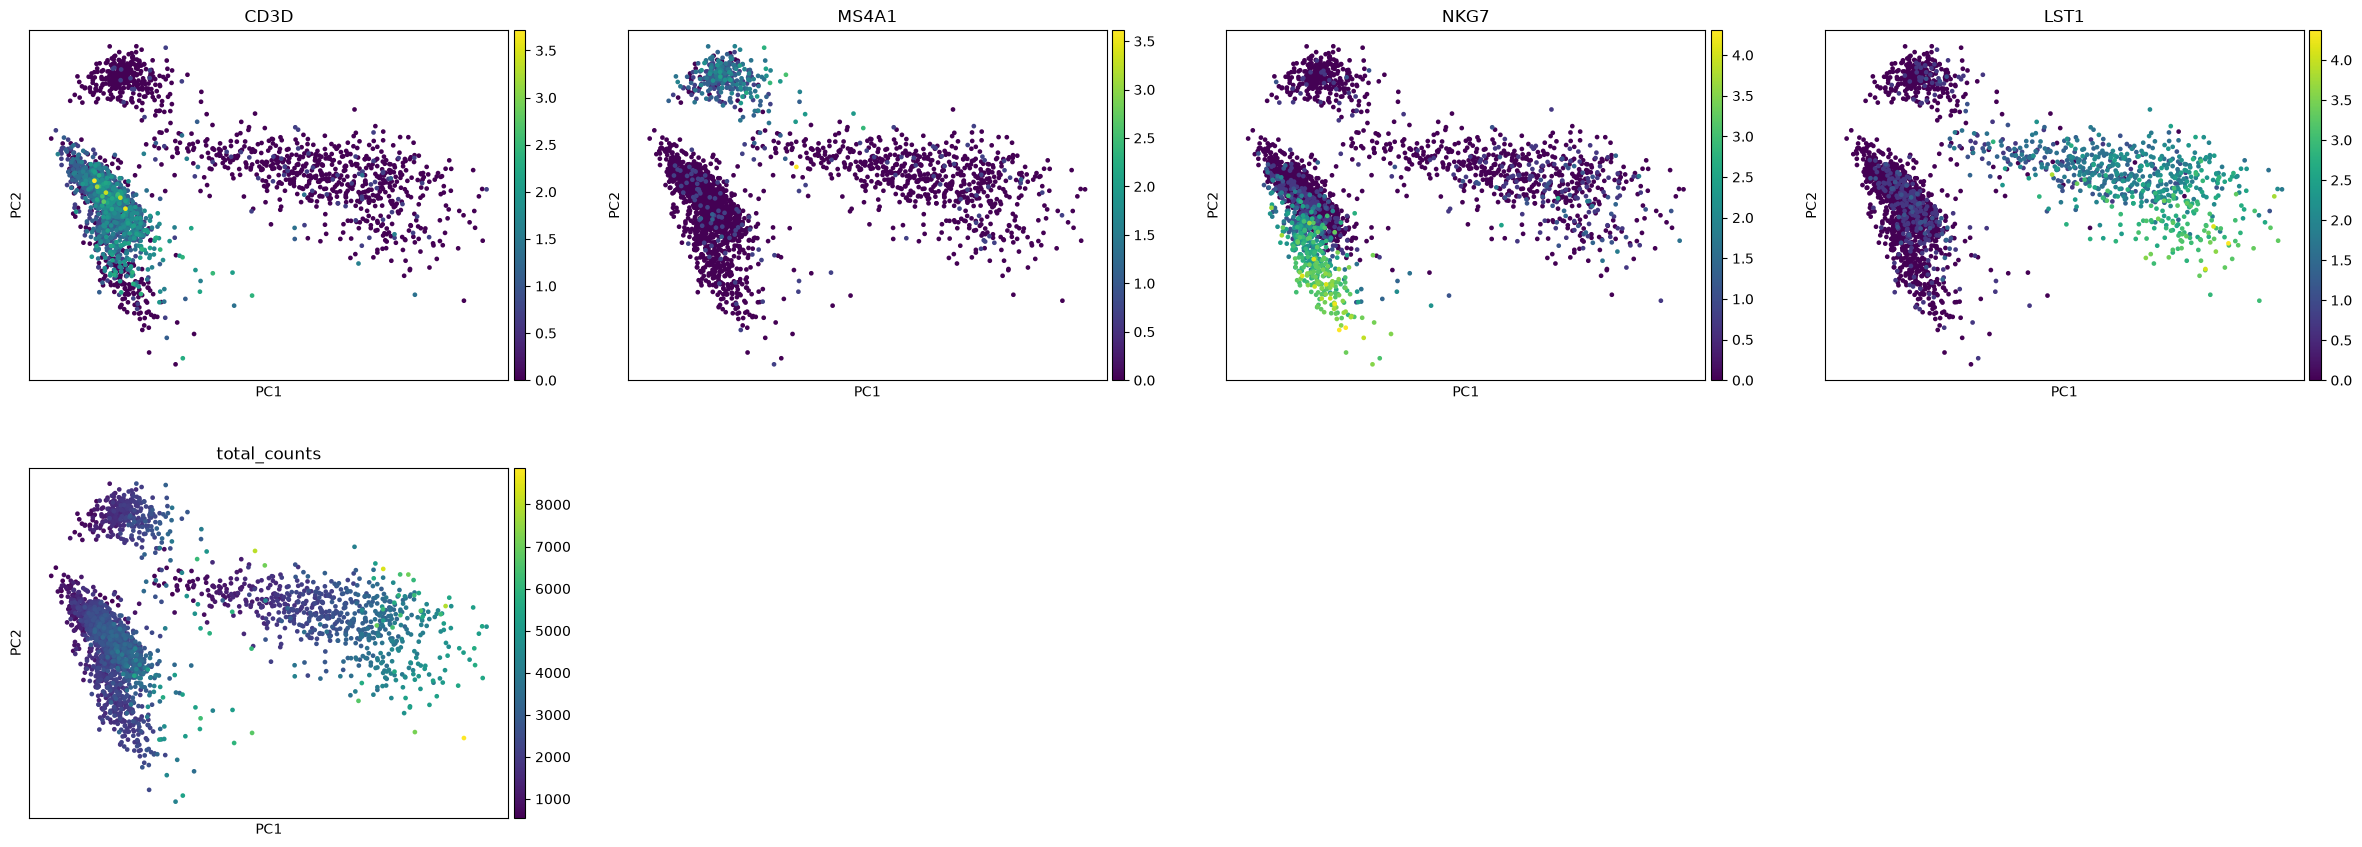

In [121]:
sc.pl.pca(a_log, color=colors)

**normalize + log1p + scale**

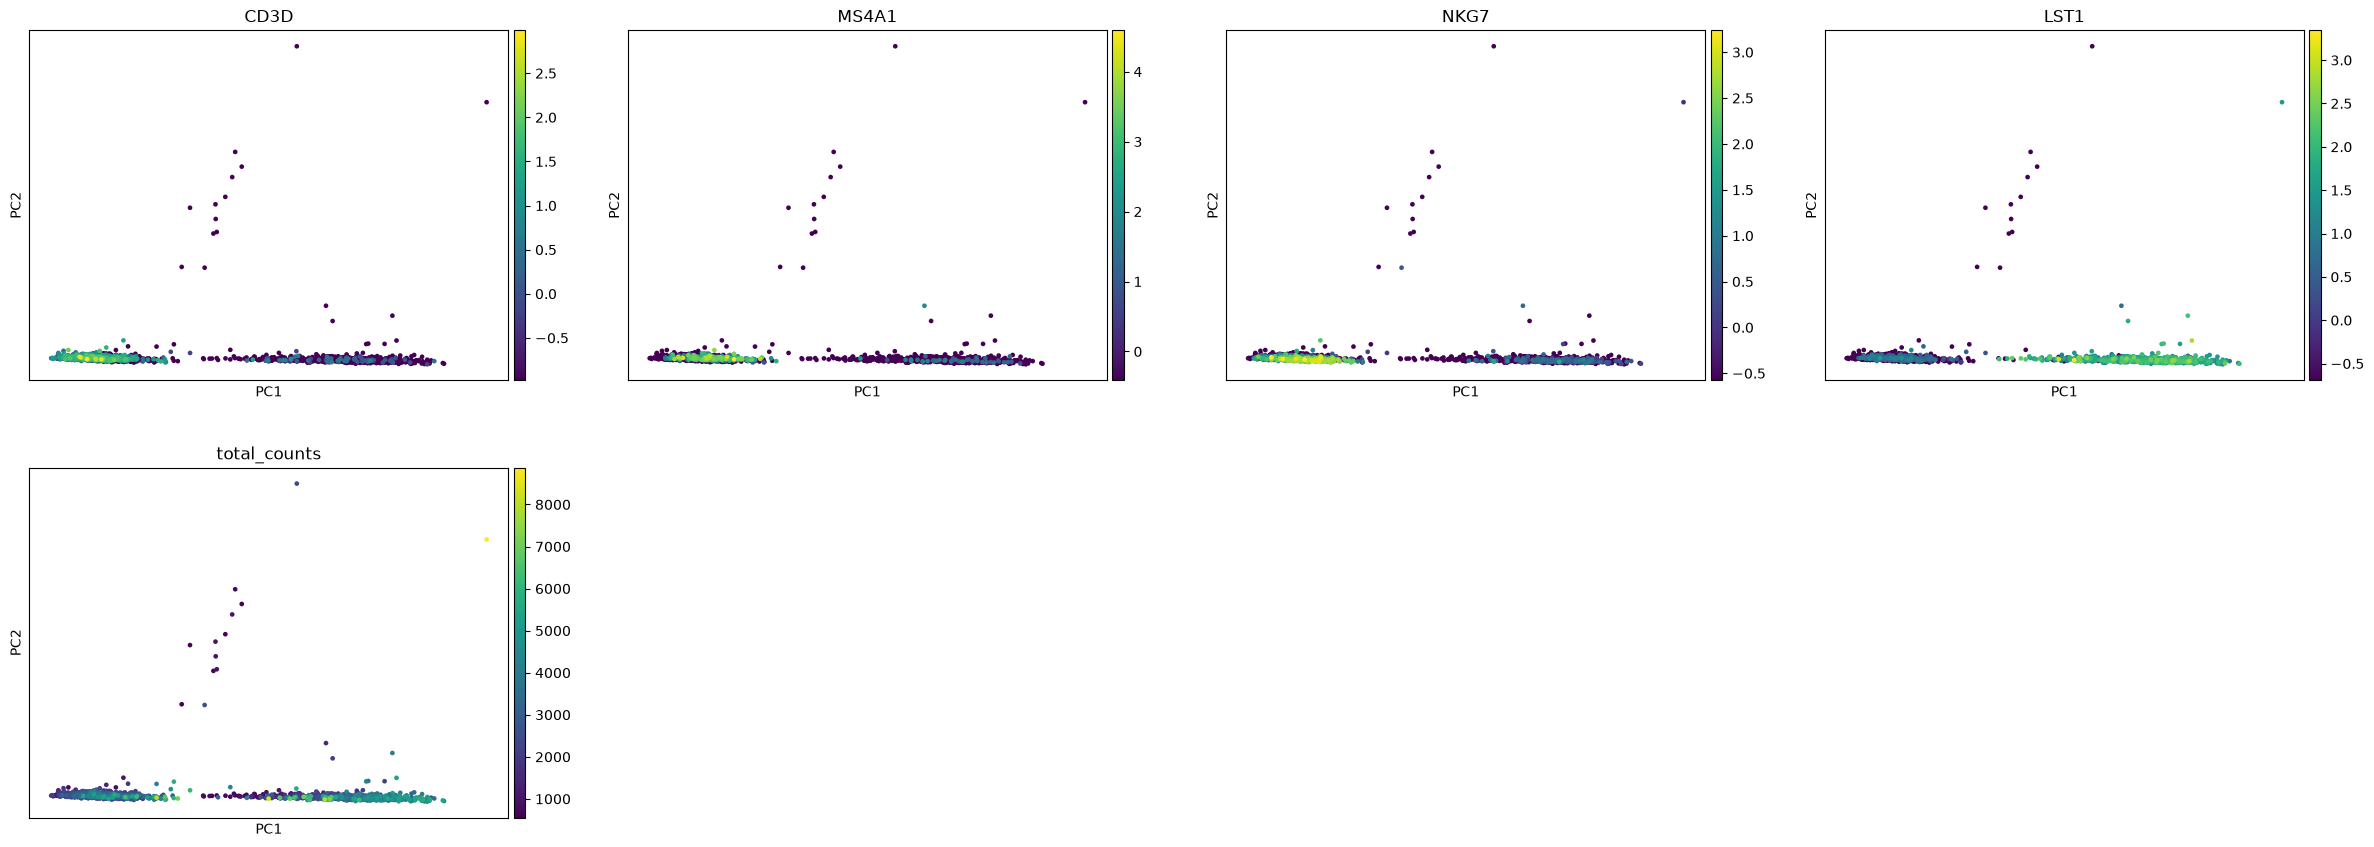

In [122]:
sc.pl.pca(a_scale, color=colors)

In [123]:
for name, ad in [("normalize + log1p", adata), ("только normalize", a_norm), ("сырые counts", a_counts), ("только log1p", a_log), ("normalize + log1p + scale", a_scale)]:
    r = np.corrcoef(ad.obsm["X_pca"][:, 0], ad.obs["total_counts"])[0, 1]
    print(f"{name}: PC1+PC2 = {ad.uns['pca']['variance_ratio'][:2].sum():.2f}, корреляция PC1 с total_counts = {r:.2f}")

normalize + log1p: PC1+PC2 = 0.13, корреляция PC1 с total_counts = 0.33
только normalize: PC1+PC2 = 0.50, корреляция PC1 с total_counts = 0.23
сырые counts: PC1+PC2 = 0.58, корреляция PC1 с total_counts = 0.57
только log1p: PC1+PC2 = 0.23, корреляция PC1 с total_counts = 0.56
normalize + log1p + scale: PC1+PC2 = 0.04, корреляция PC1 с total_counts = 0.38


- **Только normalize** - клетки вытянуты в галочку, группы почти не разделяются, B- и NK-клетки слиты с T-клетками. PC1 и PC2 объясняют 50% дисперсии, но это дисперсия нескольких генов с огромной экспрессией
- **Сырые counts** - то же самое, плюс PC1 сильно связана с `total_counts` (0.57), клетки разделяются по глубине секвенирования
- **Только log1p** - группы разделяются почти как в обычном анализе, но связь PC1 с `total_counts` высокая (0.56) - моноциты растянуты по глубине.
- **normalize+log1p** - группы разделены лучше всего, связь с глубиной меньше всего (0.33)
- **+scale** - PC1 разделяет типы клеток, но PC2 съедают несколько отдельных клеток-выбросов. Scale делает все гены одинаково важными, и редкий ген, который есть в паре клеток, получает огромные значения.

**Что сильнее влияет - нормализация или логарифм?** Логарифм. Без логарифма PCA ломается совсем, а без нормализации группы видно, только примешивается глубина.

**Сильно ли помогает scale?** Здесь - нет, стало даже хуже

**Что даёт каждая процедура:**
- **Нормализация** - делает клетки сравнимыми: убирает разницу в глубине секвенирования. Без неё PCA частично разделяет клетки по числу UMI
- **Логарифм** - сжимает большие числа. Без него были бы только несколько генов с огромной экспрессией, потому что у них огромная дисперсия
- **Стандартизация (scale)** - делает дисперсию каждого гена равной 1, чтобы все гены весили одинаково

**Все ли нужно делать перед PCA?** Нормализацию и логарифм - да, без них PCA показывает технику, а не биологию. Scale нет.

## Дополнительное задание. Клеточный цикл и PCA

Используйте наборы генов фаз S и G2/M, чтобы вычислить оценки активности программ клеточного цикла для каждой клетки.

Определите предполагаемую фазу клеточного цикла и постройте PCA, окрашенный по:

- `S_score`
- `G2M_score`
- `phase`

**Вопросы:** Разделяются ли клетки по фазам клеточного цикла? Можно ли обнаружить связь клеточного цикла с PC1 или PC2? Почему клетки одного типа могут отличаться по экспрессии генов клеточного цикла?

Списки генов фаз S и G2/M мне дал чат жпт, сказал, что это "классический набор из Tirosh et al., 2016"

In [126]:
s_genes = ["MCM5", "PCNA", "TYMS", "FEN1", "MCM2", "MCM4", "RRM1", "UNG", "GINS2", "MCM6", "CDCA7", "DTL", "PRIM1",
           "UHRF1", "MLF1IP", "HELLS", "RFC2", "RPA2", "NASP", "RAD51AP1", "GMNN", "WDR76", "SLBP", "CCNE2", "UBR7",
           "POLD3", "MSH2", "ATAD2", "RAD51", "RRM2", "CDC45", "CDC6", "EXO1", "TIPIN", "DSCC1", "BLM", "CASP8AP2",
           "USP1", "CLSPN", "POLA1", "CHAF1B", "BRIP1", "E2F8"]

g2m_genes = ["HMGB2", "CDK1", "NUSAP1", "UBE2C", "BIRC5", "TPX2", "TOP2A", "NDC80", "CKS2", "NUF2", "CKS1B", "MKI67",
             "TMPO", "CENPF", "TACC3", "FAM64A", "SMC4", "CCNB2", "CKAP2L", "CKAP2", "AURKB", "BUB1", "KIF11", "ANP32E",
             "TUBB4B", "GTSE1", "KIF20B", "HJURP", "CDCA3", "HN1", "CDC20", "TTK", "CDC25C", "KIF2C", "RANGAP1", "NCAPD2",
             "DLGAP5", "CDCA2", "CDCA8", "ECT2", "KIF23", "HMMR", "AURKA", "PSRC1", "ANLN", "LBR", "CKAP5", "CENPE",
             "CTCF", "NEK2", "G2E3", "GAS2L3", "CBX5", "CENPA"]

s_genes = [g for g in s_genes if g in adata.var_names]
g2m_genes = [g for g in g2m_genes if g in adata.var_names]

sc.tl.score_genes_cell_cycle(adata, s_genes=s_genes, g2m_genes=g2m_genes)
adata.obs["phase"].value_counts()

phase
G1     1685
S       866
G2M      87
Name: count, dtype: int64

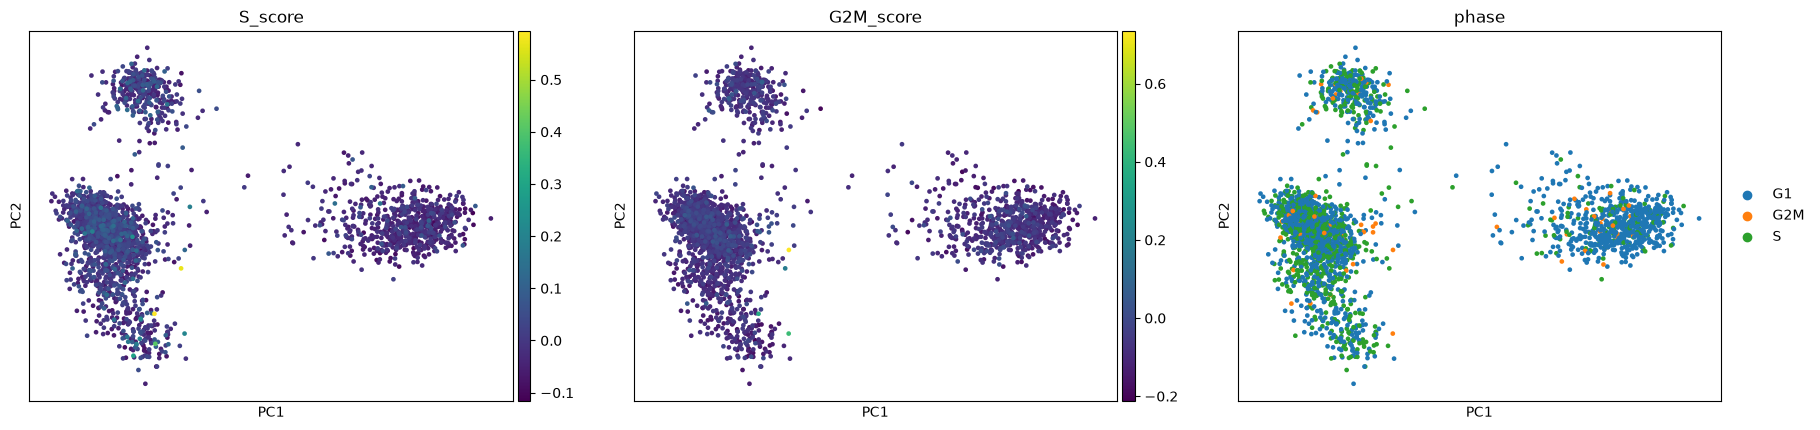

In [129]:
sc.pl.pca(adata, color=["S_score", "G2M_score", "phase"])

In [132]:
for m in ["S_score", "G2M_score"]:
    r1 = np.corrcoef(adata.obsm["X_pca"][:, 0], adata.obs[m])[0, 1]
    r2 = np.corrcoef(adata.obsm["X_pca"][:, 1], adata.obs[m])[0, 1]
    print(f"{m}: PC1 {r1:.2f}, PC2 {r2:.2f}")

S_score: PC1 -0.25, PC2 -0.01
G2M_score: PC1 -0.08, PC2 0.05


**Разделяются ли клетки по фазам?** Вообще нет

**Связь с PC1 или PC2?** Слабая, вывела выше. Небольшая связь `S_score` с PC1 скорее потому, что у лимфоцитов и моноцитов разный фоновый уровень этих генов

**Почему клетки одного типа могут отличаться по генам цикла?** Потому что клетки одного типа могут находиться в разных фазах :)